# FIFA 20 Player Data Analysis | PRCP-1004

**Project:** PRCP-1004 — FIFA 20 Player Data Analysis  
**Dataset:** `players_20.csv`  
**Notebook structure:** Task 1 (complete data analysis), Task 2 (skill-based player clustering), Task 3(a–c) (the three required questions), model comparison, challenges faced, and final conclusion.

The notebook keeps the original dataset unchanged and creates separate analysis datasets for clustering.

# TASK 1 — COMPLETE DATA ANALYSIS REPORT

Dataset understanding, data-quality assessment, exploratory data analysis, and supplementary player, club, market-value, and nationality analysis.

## 1. Dataset Understanding

In [1]:

# ==========================================================
# DATASET LOADING - ROBUST FILE PATH HANDLING
# ==========================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Check current working directory
CURRENT_PATH = Path.cwd()

print("Current Working Directory:")
print(CURRENT_PATH)

# Search for the FIFA dataset in the current folder
# and its subfolders
dataset_files = list(CURRENT_PATH.rglob("players_20.csv"))

# Also check the parent folder and its subfolders
if not dataset_files:
    dataset_files = list(
        CURRENT_PATH.parent.rglob("players_20.csv")
    )

# Load dataset if found
if dataset_files:

    DATA_PATH = dataset_files[0]

    fifa = pd.read_csv(DATA_PATH)

    print("\nDataset Loaded Successfully!")
    print("Dataset Location:", DATA_PATH)
    print("Dataset Shape:", fifa.shape)

    display(fifa.head())

else:

    print("\nDataset Not Found!")
    print("Please locate players_20.csv manually.")
    print("Notebook directory:", CURRENT_PATH)


Current Working Directory:
C:\Users\NAVEEN\OneDrive\Desktop\Intern\FIFA\Python\.ipynb_checkpoints

Dataset Loaded Successfully!
Dataset Location: C:\Users\NAVEEN\OneDrive\Desktop\Intern\FIFA\Python\players_20.csv
Dataset Shape: (18278, 104)


,sofifa_id,player_url,short_name,long_name,age,dob,height_cm,weight_kg,nationality,club,...,lwb,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb
0,158023,https://sofifa.com/player/158023/lionel-messi/...,L. Messi,Lionel Andrés Messi Cuccittini,32,1987-06-24,170,72,Argentina,FC Barcelona,...,68+2,66+2,66+2,66+2,68+2,63+2,52+2,52+2,52+2,63+2
1,20801,https://sofifa.com/player/20801/c-ronaldo-dos-...,Cristiano Ronaldo,Cristiano Ronaldo dos Santos Aveiro,34,1985-02-05,187,83,Portugal,Juventus,...,65+3,61+3,61+3,61+3,65+3,61+3,53+3,53+3,53+3,61+3
2,190871,https://sofifa.com/player/190871/neymar-da-sil...,Neymar Jr,Neymar da Silva Santos Junior,27,1992-02-05,175,68,Brazil,Paris Saint-Germain,...,66+3,61+3,61+3,61+3,66+3,61+3,46+3,46+3,46+3,61+3
3,200389,https://sofifa.com/player/200389/jan-oblak/20/...,J. Oblak,Jan Oblak,26,1993-01-07,188,87,Slovenia,Atlético Madrid,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,183277,https://sofifa.com/player/183277/eden-hazard/2...,E. Hazard,Eden Hazard,28,1991-01-07,175,74,Belgium,Real Madrid,...,66+3,63+3,63+3,63+3,66+3,61+3,49+3,49+3,49+3,61+3


In [2]:
display(fifa.head(5))
print('Shape:', fifa.shape)
print('Column types:')
display(fifa.dtypes.value_counts().rename_axis('dtype').to_frame('columns'))
print('Unique player IDs:', fifa['sofifa_id'].nunique())
print('Non-null player names:', fifa['short_name'].notna().sum())
display(fifa[['age','overall','potential','value_eur','wage_eur']].describe().T)

,sofifa_id,player_url,short_name,long_name,age,dob,height_cm,weight_kg,nationality,club,...,lwb,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb
0,158023,https://sofifa.com/player/158023/lionel-messi/...,L. Messi,Lionel Andrés Messi Cuccittini,32,1987-06-24,170,72,Argentina,FC Barcelona,...,68+2,66+2,66+2,66+2,68+2,63+2,52+2,52+2,52+2,63+2
1,20801,https://sofifa.com/player/20801/c-ronaldo-dos-...,Cristiano Ronaldo,Cristiano Ronaldo dos Santos Aveiro,34,1985-02-05,187,83,Portugal,Juventus,...,65+3,61+3,61+3,61+3,65+3,61+3,53+3,53+3,53+3,61+3
2,190871,https://sofifa.com/player/190871/neymar-da-sil...,Neymar Jr,Neymar da Silva Santos Junior,27,1992-02-05,175,68,Brazil,Paris Saint-Germain,...,66+3,61+3,61+3,61+3,66+3,61+3,46+3,46+3,46+3,61+3
3,200389,https://sofifa.com/player/200389/jan-oblak/20/...,J. Oblak,Jan Oblak,26,1993-01-07,188,87,Slovenia,Atlético Madrid,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,183277,https://sofifa.com/player/183277/eden-hazard/2...,E. Hazard,Eden Hazard,28,1991-01-07,175,74,Belgium,Real Madrid,...,66+3,63+3,63+3,63+3,66+3,61+3,49+3,49+3,49+3,61+3


Shape: (18278, 104)
Column types:


,columns
dtype,
int64,45
str,43
float64,16


Unique player IDs: 18278
Non-null player names: 18278


,count,mean,std,min,25%,50%,75%,max
age,18278.0,2.528329e+01,4.656964e+00,16.0,22.0,25.0,29.0,42.0
overall,18278.0,6.624499e+01,6.949953e+00,48.0,62.0,66.0,71.0,94.0
potential,18278.0,7.154689e+01,6.139669e+00,49.0,67.0,71.0,75.0,95.0
value_eur,18278.0,2.484038e+06,5.585481e+06,0.0,325000.0,700000.0,2100000.0,105500000.0
wage_eur,18278.0,9.456943e+03,2.135171e+04,0.0,1000.0,3000.0,8000.0,565000.0


**Interpretation:** Each row represents a player record identified by `sofifa_id`. The number of non-null names is not necessarily the number of unique players; the ID is the preferred identity key. Numerical summaries describe the sample, not the effect of a feature on performance.

## 2. Data Quality Assessment

### 2.1 Missing-value overview — one canonical summary

In [3]:
n_rows, n_features = fifa.shape
missing_summary = pd.DataFrame({
    'Missing_Count': fifa.isna().sum(),
    'Missing_Percent': fifa.isna().mean().mul(100).round(2),
    'Available_Count': fifa.notna().sum()
}).rename_axis('Feature').sort_values(['Missing_Count','Feature'], ascending=[False, True])
missing_summary['Missing_Class'] = pd.cut(
    missing_summary['Missing_Percent'],
    bins=[-0.01, 0, 5, 30, 60, 100],
    labels=['None','Low (0–5%)','Moderate (5–30%)','High (30–60%)','Very high (>60%)']
)
display(missing_summary.head(25))
print('Columns without missing values:', int((missing_summary.Missing_Count == 0).sum()))
print('Columns with missing values:', int((missing_summary.Missing_Count > 0).sum()))
print('Rows with at least one missing value:', int(fifa.isna().any(axis=1).sum()))
print('Missing cells:', int(fifa.isna().sum().sum()))
print('Missing cell percentage:', round(fifa.isna().to_numpy().mean()*100,2))

,Missing_Count,Missing_Percent,Available_Count,Missing_Class
Feature,,,,
loaned_from,17230,94.27,1048,Very high (>60%)
nation_jersey_number,17152,93.84,1126,Very high (>60%)
nation_position,17152,93.84,1126,Very high (>60%)
player_tags,16779,91.80,1499,Very high (>60%)
gk_diving,16242,88.86,2036,Very high (>60%)
gk_handling,16242,88.86,2036,Very high (>60%)
gk_kicking,16242,88.86,2036,Very high (>60%)
gk_positioning,16242,88.86,2036,Very high (>60%)
gk_reflexes,16242,88.86,2036,Very high (>60%)


Columns without missing values: 56
Columns with missing values: 48
Rows with at least one missing value: 18278
Missing cells: 244935
Missing cell percentage: 12.89


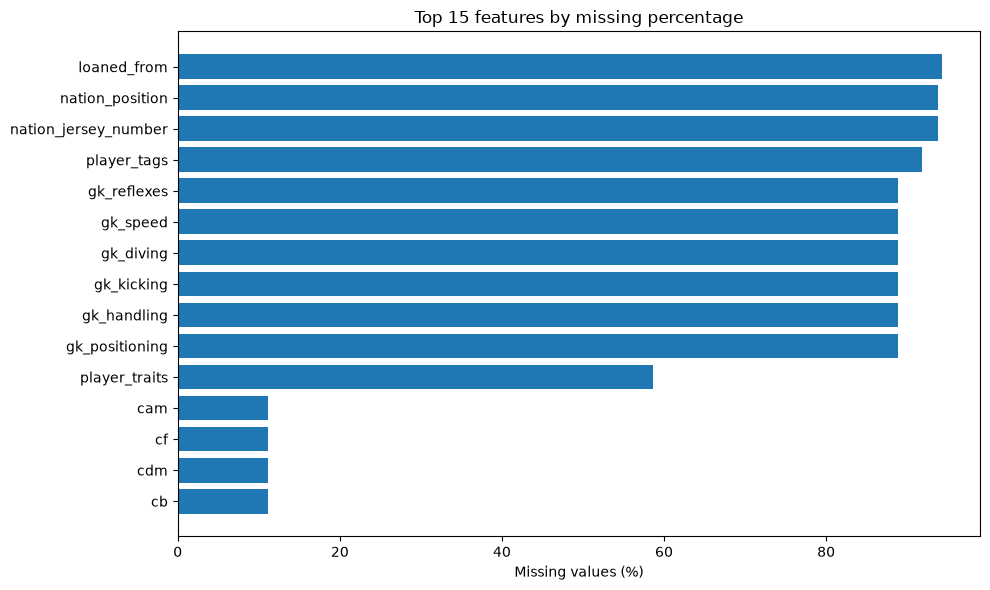

In [4]:
top_missing = missing_summary.query('Missing_Count > 0').head(15).sort_values('Missing_Percent')
fig, ax = plt.subplots(figsize=(10,6))
ax.barh(top_missing.index, top_missing['Missing_Percent'])
ax.set(xlabel='Missing values (%)', title='Top 15 features by missing percentage')
plt.tight_layout(); plt.show()

**Interpretation:** High missingness alone does not prove a data-quality error. Some FIFA attributes apply only to particular roles or player circumstances. Preserve the original missingness until the relevant population and purpose of each field are checked.

### 2.2 Duplicate records and player identity

In [5]:
print('Exact duplicate rows:', int(fifa.duplicated().sum()))
print('Duplicate sofifa_id values:', int(fifa['sofifa_id'].duplicated().sum()))
name_counts = fifa['short_name'].value_counts(dropna=True)
repeated_names = name_counts[name_counts > 1]
print('Distinct short names shared by multiple records:', len(repeated_names))
print('Records with repeated short names:', int(fifa['short_name'].isin(repeated_names.index).sum()))
if not repeated_names.empty:
    sample_names = repeated_names.head(10).index
    display(fifa.loc[fifa['short_name'].isin(sample_names),
                     ['sofifa_id','short_name','long_name','nationality','club','age']]
            .sort_values(['short_name','sofifa_id']).head(35))

Exact duplicate rows: 0
Duplicate sofifa_id values: 0
Distinct short names shared by multiple records: 696
Records with repeated short names: 1620


,sofifa_id,short_name,long_name,nationality,club,age
11946,190235,J. Clarke,Jordan Clarke,England,Scunthorpe United,27
12758,219436,J. Clarke,Josh Clarke,England,Brentford,24
10958,229126,J. Clarke,James Clarke,England,Walsall,29
17446,241639,J. Clarke,Jack Clarke,Republic of Ireland,Aston Villa,20
7700,242908,J. Clarke,Jack Clarke,England,Leeds United,18
16498,243292,J. Clarke,James Clarke,Republic of Ireland,Mansfield Town,19
4485,178566,J. García,Javier Hernán García,Argentina,Racing Club,32
13895,214347,J. García,Jhon Stiwar García Mena,Colombia,Jaguares de Córdoba,28
10954,227377,J. García,John Edison García Zabala,Colombia,La Equidad,30
18133,240286,J. García,Joel Raymundo García Chacón,Mexico,Santos Laguna,21


**Decision:** A shared `short_name` is not evidence of a duplicate player. Do not drop players based on names. Check `sofifa_id` for duplicate identities and inspect exact duplicates separately.

### 2.3 Date parsing and consistency

In [6]:
date_checks = []
for col in ['dob','joined']:
    parsed = pd.to_datetime(fifa[col], format='%Y-%m-%d', errors='coerce')
    date_checks.append({'Feature': col, 'Non_Missing': int(fifa[col].notna().sum()),
                        'Invalid_Nonmissing': int((fifa[col].notna() & parsed.isna()).sum()),
                        'Min_Date': parsed.min(), 'Max_Date': parsed.max()})
display(pd.DataFrame(date_checks))
print('Dates are checked without changing the original dataframe.')

,Feature,Non_Missing,Invalid_Nonmissing,Min_Date,Max_Date
0,dob,18278,0,1977-01-21,2002-08-08
1,joined,16990,0,1998-01-01,2019-08-18


Dates are checked without changing the original dataframe.


### 2.4 Categorical consistency

In [7]:
categorical_cols = fifa.select_dtypes(include=['object','string','category']).columns
cat_quality = pd.DataFrame({
    'Nonmissing': fifa[categorical_cols].notna().sum(),
    'Unique_Nonmissing': fifa[categorical_cols].nunique(dropna=True),
    'Missing_Percent': fifa[categorical_cols].isna().mean().mul(100).round(2)
}).sort_values('Unique_Nonmissing', ascending=False)
display(cat_quality)
for col in ['nationality','club','preferred_foot','work_rate','body_type']:
    print(f'\n{col}:')
    display(fifa[col].value_counts(dropna=False).head(10).to_frame('Count'))

,Nonmissing,Unique_Nonmissing,Missing_Percent
player_url,18278,18278,0.00
long_name,18278,18218,0.00
short_name,18278,17354,0.00
dob,18278,6142,0.00
joined,16990,1760,7.05
player_traits,7566,921,58.61
club,18278,698,0.00
player_positions,18278,643,0.00
loaned_from,1048,316,94.27
nationality,18278,162,0.00



nationality:


,Count
nationality,
England,1667
Germany,1216
Spain,1035
France,984
Argentina,886
Brazil,824
Italy,732
Colombia,591
Japan,453



club:


,Count
club,
FC Barcelona,33
Juventus,33
Paris Saint-Germain,33
Atlético Madrid,33
Real Madrid,33
Manchester City,33
Liverpool,33
Tottenham Hotspur,33
Manchester United,33



preferred_foot:


,Count
preferred_foot,
Right,13960
Left,4318



work_rate:


,Count
work_rate,
Medium/Medium,9875
High/Medium,3216
Medium/High,1718
High/High,986
Medium/Low,886
High/Low,684
Low/Medium,461
Low/High,417
Low/Low,35



body_type:


,Count
body_type,
Normal,10750
Lean,6505
Stocky,1016
Messi,1
C. Ronaldo,1
Neymar,1
PLAYER_BODY_TYPE_25,1
Courtois,1
Shaqiri,1


In [8]:
whitespace_results = []
for col in ['club','player_tags','short_name']:
    values = fifa[col].dropna().astype(str)
    whitespace_results.append({'Feature': col,
        'Leading_or_Trailing_Whitespace': int(values.ne(values.str.strip()).sum())})
display(pd.DataFrame(whitespace_results))
name_variants = (fifa['short_name'].dropna().groupby(fifa['short_name'].dropna().str.casefold()).nunique())
print('Case-normalized name groups with >1 written form:', int(name_variants.gt(1).sum()))

,Feature,Leading_or_Trailing_Whitespace
0,club,25
1,player_tags,42
2,short_name,0


Case-normalized name groups with >1 written form: 2


**Interpretation:** Count and inspect anomalies before changing text. Different names, spellings and capitalization can refer to different people; do not automatically merge records.

### 2.5 Numerical quality, ranges and statistical outliers

In [9]:
num = fifa.select_dtypes(include='number')
num_quality = pd.DataFrame({
    'Missing_Count': num.isna().sum(),
    'Zero_Count': num.eq(0).sum(),
    'Negative_Count': num.lt(0).sum(),
    'Min': num.min(), 'Max': num.max()
})
display(num_quality.loc[[x for x in ['age','height_cm','weight_kg','overall','potential','value_eur','wage_eur','release_clause_eur'] if x in num_quality.index]])
validation_rules = {'age': (15, 50), 'height_cm': (140, 220), 'weight_kg': (40, 130),
                    'overall': (1,99), 'potential': (1,99), 'weak_foot': (1,5),
                    'skill_moves': (1,5)}
checks=[]
for col, (lo,hi) in validation_rules.items():
    if col in fifa.columns:
        bad = fifa[col].notna() & ~fifa[col].between(lo,hi)
        checks.append({'Feature':col, 'Plausibility_Lower':lo,'Plausibility_Upper':hi,
                       'Outside_Illustrative_Range':int(bad.sum())})
display(pd.DataFrame(checks))

,Missing_Count,Zero_Count,Negative_Count,Min,Max
age,0,0,0,16.0,42.0
height_cm,0,0,0,156.0,205.0
weight_kg,0,0,0,50.0,110.0
overall,0,0,0,48.0,94.0
potential,0,0,0,49.0,95.0
value_eur,0,250,0,0.0,105500000.0
wage_eur,0,240,0,0.0,565000.0
release_clause_eur,1298,0,0,13000.0,195800000.0


,Feature,Plausibility_Lower,Plausibility_Upper,Outside_Illustrative_Range
0,age,15,50,0
1,height_cm,140,220,0
2,weight_kg,40,130,0
3,overall,1,99,0
4,potential,1,99,0
5,weak_foot,1,5,0
6,skill_moves,1,5,0


**Caution:** The age, height and weight limits above are illustrative plausibility screens, not official FIFA data rules. A flagged value needs investigation; it is not automatically wrong. Zero wages or financial values may be valid or context-dependent.

In [10]:
continuous = ['age','height_cm','weight_kg','overall','potential','value_eur','wage_eur']
iqr_rows=[]
for col in continuous:
    s=fifa[col].dropna()
    q1,q3=s.quantile([.25,.75]); iqr=q3-q1
    lower,upper=q1-1.5*iqr,q3+1.5*iqr
    iqr_rows.append({'Feature':col,'IQR_Lower':lower,'IQR_Upper':upper,
                     'Flagged_Count':int(((s<lower)|(s>upper)).sum()),
                     'Flagged_Percent':round(((s<lower)|(s>upper)).mean()*100,2)})
display(pd.DataFrame(iqr_rows))

,Feature,IQR_Lower,IQR_Upper,Flagged_Count,Flagged_Percent
0,age,11.5,39.5,19,0.10
1,height_cm,163.5,199.5,89,0.49
2,weight_kg,55.0,95.0,73,0.40
3,overall,48.5,84.5,151,0.83
4,potential,55.0,87.0,145,0.79
5,value_eur,-2337500.0,4762500.0,2511,13.74
6,wage_eur,-9500.0,18500.0,2360,12.91


**Decision:** IQR flags are statistical extremes, not confirmed errors. High-value footballers can legitimately be extreme; no rows are deleted based solely on these flags.

### 2.6 Missingness by player role (goalkeeper vs outfield)

In [11]:
# Derive a helper category without modifying the 104-column source dataframe.
primary_position = fifa['player_positions'].fillna('').str.split(',').str[0].str.strip()
player_category = pd.Series(np.where(primary_position.eq('GK'), 'Goalkeeper', 'Outfield Player'),
                            index=fifa.index, name='Player_Category')
role_missing = pd.DataFrame({
    'Player_Count': player_category.value_counts(),
    'Missing_Cells': fifa.isna().sum(axis=1).groupby(player_category).sum()
})
role_missing['Missing_Percent'] = (
    role_missing['Missing_Cells'] / (role_missing['Player_Count'] * n_features) * 100
).round(2)
display(role_missing)
print('Denominator uses original number of features:', n_features)

,Player_Count,Missing_Cells,Missing_Percent
Player_Category,,,
Goalkeeper,2036,74667,35.26
Outfield Player,16242,170268,10.08


Denominator uses original number of features: 104


**Important correction:** The denominator uses the original CSV column count, not the count after adding a helper category. This prevents a subtle underestimation of missing percentages.

### 2.7 Goalkeeper-specific attributes and structural missingness

In [12]:
gk_cols = ['gk_diving','gk_handling','gk_kicking','gk_reflexes','gk_speed','gk_positioning']
role_gk_missing = pd.DataFrame({
    'Feature':gk_cols,
    'GK_Missing': [int(fifa.loc[player_category.eq('Goalkeeper'), col].isna().sum()) for col in gk_cols],
    'GK_Missing_Percent': [round(fifa.loc[player_category.eq('Goalkeeper'), col].isna().mean()*100,2) for col in gk_cols],
    'Outfield_Missing': [int(fifa.loc[player_category.eq('Outfield Player'), col].isna().sum()) for col in gk_cols],
    'Outfield_Missing_Percent': [round(fifa.loc[player_category.eq('Outfield Player'), col].isna().mean()*100,2) for col in gk_cols]
})
display(role_gk_missing)

,Feature,GK_Missing,GK_Missing_Percent,Outfield_Missing,Outfield_Missing_Percent
0,gk_diving,0,0.0,16242,100.0
1,gk_handling,0,0.0,16242,100.0
2,gk_kicking,0,0.0,16242,100.0
3,gk_reflexes,0,0.0,16242,100.0
4,gk_speed,0,0.0,16242,100.0
5,gk_positioning,0,0.0,16242,100.0


**Interpretation:** These six `gk_` columns are role-specific ratings. Missing values for outfield players are structurally expected and should not be filled with the goalkeeper average. The dataset also has separate `goalkeeping_` skill columns; do not confuse the two groups.

### 2.8 High-missing feature investigation

In [13]:
investigate = ['loaned_from','nation_position','nation_jersey_number','player_tags','player_traits']
review = missing_summary.loc[investigate, ['Missing_Count','Available_Count','Missing_Percent']]
display(review)
for col in investigate:
    print(f'\n{col} — top observed values (excluding missing):')
    display(fifa[col].value_counts().head(8).to_frame('Count'))

,Missing_Count,Available_Count,Missing_Percent
Feature,,,
loaned_from,17230,1048,94.27
nation_position,17152,1126,93.84
nation_jersey_number,17152,1126,93.84
player_tags,16779,1499,91.80
player_traits,10712,7566,58.61



loaned_from — top observed values (excluding missing):


,Count
loaned_from,
Sassuolo,17
Atalanta,17
Inter,14
SL Benfica,14
Racing Club,13
Genoa,13
Chelsea,12
Real Madrid,12



nation_position — top observed values (excluding missing):


,Count
nation_position,
SUB,587
GK,49
LCB,49
RCB,49
LB,46
RB,46
ST,43
RCM,36



nation_jersey_number — top observed values (excluding missing):


,Count
nation_jersey_number,
1.0,49
9.0,49
3.0,49
15.0,49
21.0,49
6.0,49
14.0,49
2.0,49



player_tags — top observed values (excluding missing):


,Count
player_tags,
#Strength,514
#Acrobat,238
#Engine,209
#Speedster,156
"#Speedster, #Acrobat",66
"#Aerial Threat, #Strength",62
#Aerial Threat,33
#Dribbler,30



player_traits — top observed values (excluding missing):


,Count
player_traits,
Early Crosser,501
Power Free-Kick,370
Long Passer (CPU AI Only),354
Crowd Favourite,296
Argues with Officials,294
Injury Prone,259
Leadership,237
"Selfish, Crowd Favourite",188


**Interpretation and next-stage decisions:** `loaned_from` may be populated only for loaned players; national-team fields may be populated only for selected players; tags and traits are optional annotations. These are plausible explanations, not verified reasons for every blank. Preserve them for now and document whether a later analysis needs each field. Avoid blanket mean/mode imputation for these columns.

### 2.9 Missingness by primary playing position

In [14]:
position_review = (pd.DataFrame({'Primary_Position':primary_position,
                                  'Missing_Cells':fifa.isna().sum(axis=1)})
                   .groupby('Primary_Position',dropna=False)
                   .agg(Player_Count=('Missing_Cells','size'),
                        Average_Missing_Cells=('Missing_Cells','mean'))
                   .sort_values('Player_Count',ascending=False))
position_review['Average_Missing_Percent'] = (position_review['Average_Missing_Cells']/n_features*100).round(2)
display(position_review.head(20))

,Player_Count,Average_Missing_Cells,Average_Missing_Percent
Primary_Position,,,
CB,3162,10.521189,10.12
ST,2582,10.496902,10.09
CM,2193,10.497036,10.09
GK,2036,36.673379,35.26
CDM,1424,10.558989,10.15
RB,1314,10.572298,10.17
LB,1303,10.627782,10.22
CAM,1146,10.400524,10.00
RM,1050,10.384762,9.99


**Why this view is useful:** Grouping by the first listed playing position avoids fragmented categories such as `RW, CF, ST`. Compare missing percentages and group sizes together; small groups may be unstable.

## 3. Data-quality decisions and handoff

In [15]:
audit = pd.DataFrame([
    {'Check':'Original records','Result':len(fifa)},
    {'Check':'Original features','Result':n_features},
    {'Check':'Missing cells','Result':int(fifa.isna().sum().sum())},
    {'Check':'Features with missing data','Result':int(fifa.isna().any().sum())},
    {'Check':'Exact duplicate rows','Result':int(fifa.duplicated().sum())},
    {'Check':'Duplicate player IDs','Result':int(fifa.sofifa_id.duplicated().sum())},
])
display(audit)
assert n_features == fifa.shape[1]
assert role_missing.Player_Count.sum() == len(fifa)
assert role_missing.Missing_Cells.sum() == fifa.isna().sum().sum()
assert (missing_summary.Missing_Count + missing_summary.Available_Count).eq(len(fifa)).all()
print('Data-quality reconciliation checks passed.')

,Check,Result
0,Original records,18278
1,Original features,104
2,Missing cells,244935
3,Features with missing data,48
4,Exact duplicate rows,0
5,Duplicate player IDs,0


Data-quality reconciliation checks passed.


### Findings and next steps

- **Keep the original CSV unchanged.** The notebook has not imputed, dropped, encoded or scaled any source features.
- **Identity:** `sofifa_id` is the unique player identifier. Repeated short names should not be removed automatically.
- **Missingness:** Role-specific goalkeeper ratings and sparse administrative/annotation fields need context-aware treatment.
- **Numerical checks:** Plausibility and IQR flags require investigation before any corrective action.
- **Preprocessing for clustering (not yet implemented):** Choose skill attributes aligned to the project statement; decide separately how to handle goalkeepers; exclude player identifiers and avoid using `overall` to drive clusters. Fit imputation and scaling on the modeling data with a reproducible pipeline.
- **Official project tasks still pending:** complete EDA; skill-based player clustering and comparison of candidate clustering methods; top-10 countries by player count; overall rating versus age; ST vs RW vs LW wage comparison; final report on challenges and limitations.

**Scope note:** A single FIFA 20 snapshot can show cross-sectional age/rating patterns, but cannot establish the exact age when an individual player stops improving. The age analysis must be framed as association, not longitudinal proof.

## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand player
characteristics, performance metrics, and distributions.

This section investigates numerical patterns, player attributes,
age-related performance, wage differences, and country-wise
player distribution to identify meaningful insights for clustering.

In [16]:
# Numerical feature overview

numerical_features = fifa.select_dtypes(include=['number']).columns

print("Total Numerical Features:", len(numerical_features))

display(
    fifa[numerical_features]
    .describe()
    .T
    .round(2)
)

Total Numerical Features: 61


,count,mean,std,min,25%,50%,75%,max
sofifa_id,18278.0,219738.86,27960.20,768.0,204445.5,226165.0,240795.75,252905.0
age,18278.0,25.28,4.66,16.0,22.0,25.0,29.00,42.0
height_cm,18278.0,181.36,6.76,156.0,177.0,181.0,186.00,205.0
weight_kg,18278.0,75.28,7.05,50.0,70.0,75.0,80.00,110.0
overall,18278.0,66.24,6.95,48.0,62.0,66.0,71.00,94.0
...,...,...,...,...,...,...,...,...
goalkeeping_diving,18278.0,16.57,17.74,1.0,8.0,11.0,14.00,90.0
goalkeeping_handling,18278.0,16.35,17.00,1.0,8.0,11.0,14.00,92.0
goalkeeping_kicking,18278.0,16.21,16.61,1.0,8.0,11.0,14.00,93.0
goalkeeping_positioning,18278.0,16.37,17.14,1.0,8.0,11.0,14.00,91.0


### 5.2 Numerical Feature Analysis

This analysis examines the statistical distribution of relevant
numerical player characteristics.

Player identifiers and goalkeeper-specific attributes are excluded
from this general overview to avoid misleading interpretations.

In [17]:
# ============================================
# NUMERICAL FEATURE ANALYSIS
# ============================================

# Identify goalkeeper-specific attributes
goalkeeper_features = [
    col for col in fifa.columns
    if col.startswith(('gk_', 'goalkeeping_'))
]

# Exclude player ID and administrative fields
excluded_features = [
    'sofifa_id',
    'team_jersey_number',
    'nation_jersey_number',
    'contract_valid_until'
]

# Select relevant numerical features
general_numerical_features = [
    col for col in fifa.select_dtypes(include='number').columns
    if col not in goalkeeper_features
    and col not in excluded_features
]

# Generate numerical summary
numerical_summary = (
    fifa[general_numerical_features]
    .describe()
    .T
    .round(2)
)

# Display numerical summary
display(numerical_summary)

,count,mean,std,min,25%,50%,75%,max
age,18278.0,25.28,4.66,16.0,22.0,25.0,29.0,42.0
height_cm,18278.0,181.36,6.76,156.0,177.0,181.0,186.0,205.0
weight_kg,18278.0,75.28,7.05,50.0,70.0,75.0,80.0,110.0
overall,18278.0,66.24,6.95,48.0,62.0,66.0,71.0,94.0
potential,18278.0,71.55,6.14,49.0,67.0,71.0,75.0,95.0
value_eur,18278.0,2484037.64,5585481.06,0.0,325000.0,700000.0,2100000.0,105500000.0
wage_eur,18278.0,9456.94,21351.71,0.0,1000.0,3000.0,8000.0,565000.0
international_reputation,18278.0,1.10,0.38,1.0,1.0,1.0,1.0,5.0
weak_foot,18278.0,2.94,0.66,1.0,3.0,3.0,3.0,5.0
skill_moves,18278.0,2.37,0.77,1.0,2.0,2.0,3.0,5.0


### Numerical Feature Distribution Analysis
This analysis examines the distribution of key numerical player
characteristics using histograms and density curves.

It helps identify the distribution patterns, skewness, and
concentration of player attributes.

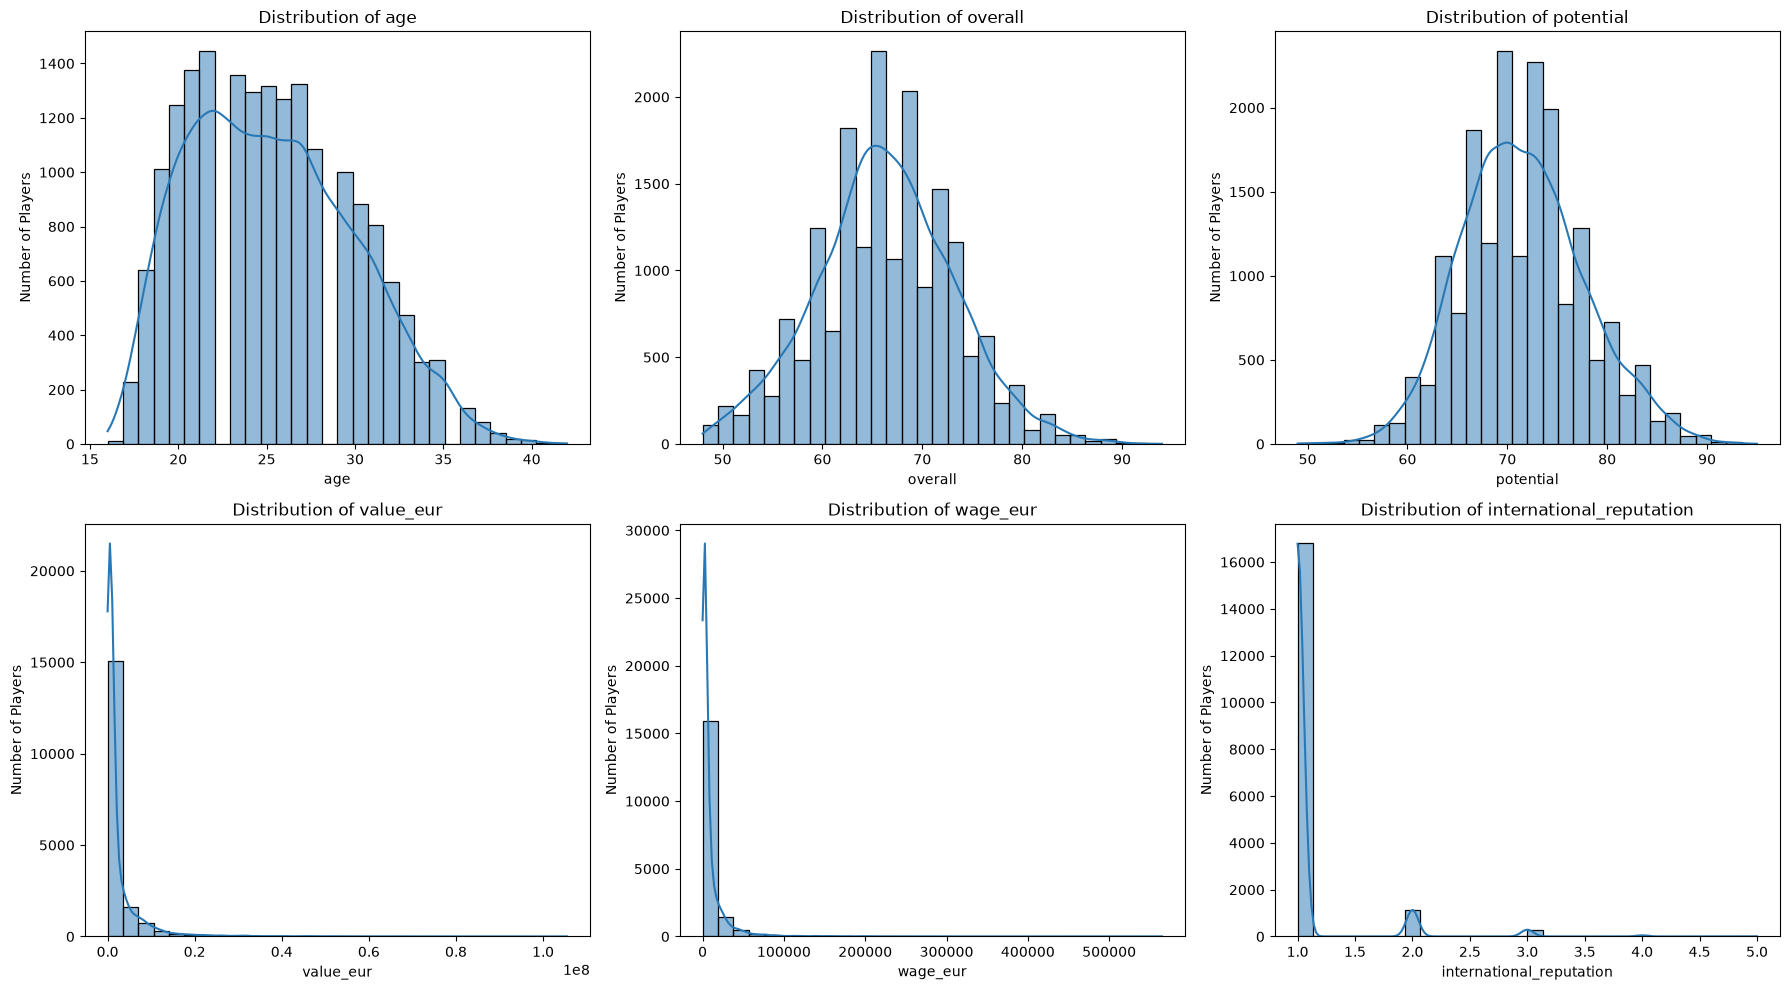

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select important numerical features
distribution_features = [
    'age',
    'overall',
    'potential',
    'value_eur',
    'wage_eur',
    'international_reputation'
]

# Plot distributions
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, col in zip(axes.flatten(), distribution_features):

    sns.histplot(
        color="#2878B5",
        data=fifa,
        x=col,
        kde=True,
        bins=30,
        ax=ax
    )

    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Number of Players')

plt.tight_layout()
plt.show()

### Observations – Numerical Feature Distribution Analysis

The distribution analysis reveals several important characteristics of FIFA 20 players.

- **Age:** The majority of players are concentrated between 20 and 30 years, indicating that the dataset primarily represents young and middle-aged professional footballers.
- **Overall Rating:** Most players have overall ratings between 60 and 75, while only a small proportion achieve exceptionally high ratings.
- **Potential:** Player potential is primarily concentrated between 65 and 80, suggesting opportunities for future development among many players.
- **Market Value:** Market value exhibits a strong positive (right) skew, indicating that a small number of highly valued players account for extremely high market values.
- **Wages:** Wage distribution is strongly right-skewed, showing substantial differences in player earnings.
- **International Reputation:** Most players have an international reputation rating of 1, while higher reputation levels are considerably less common.

**Conclusion:** Age, overall rating, and potential show relatively concentrated distributions, whereas market value and wages exhibit substantial positive skewness. These patterns highlight differences in player performance, potential, and economic value.

## Numerical Feature Correlation Analysis

This analysis examines the relationships between important numerical
features of FIFA 20 players using correlation coefficients.

It helps identify associations between player age, performance,
potential, market value, and wages.

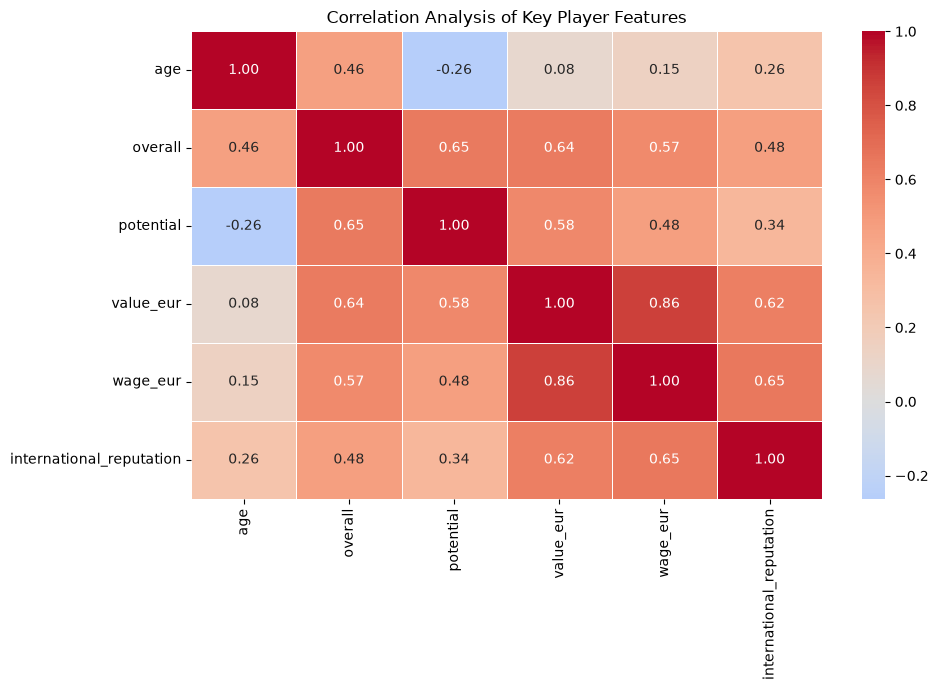

In [19]:
# Select relevant numerical features
correlation_features = [
    'age',
    'overall',
    'potential',
    'value_eur',
    'wage_eur',
    'international_reputation'
]

# Calculate correlation matrix
correlation_matrix = fifa[correlation_features].corr()

# Visualize correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Correlation Analysis of Key Player Features')
plt.tight_layout()
plt.show()

### Observations – Numerical Feature Correlation Analysis

The correlation analysis identifies several relationships among FIFA 20 player characteristics.

- **Age and Overall Rating (0.46):** A moderate positive relationship indicates that older players tend to have higher overall ratings within this dataset.
- **Overall Rating and Potential (0.65):** A strong positive relationship suggests that players with higher current ratings generally have higher potential ratings.
- **Overall Rating and Market Value (0.64):** A strong positive association indicates that highly rated players generally have higher market values.
- **Overall Rating and Wage (0.57):** A moderate positive relationship suggests that players with better overall ratings tend to receive higher wages.
- **Market Value and Wage (0.86):** A very strong positive relationship indicates that players with higher market values generally receive higher wages.
- **International Reputation and Wage (0.65):** A strong positive association suggests that internationally recognized players tend to receive higher wages.
- **Age and Potential (-0.26):** A weak negative relationship indicates that potential ratings tend to decrease slightly as player age increases.

**Conclusion:** Market value and wage exhibit the strongest positive correlation (0.86). Overall rating is also positively associated with potential, market value, and wages. These relationships provide useful insights into player performance and economic valuation.

## Categorical Feature Analysis

This section examines the distribution of categorical player characteristics
to understand the composition of the FIFA 20 dataset.

The analysis focuses on player positions, nationalities, clubs,
preferred foot, and work rates.

In [20]:
# Count players by their primary position
position_counts = fifa['team_position'].value_counts()

# Display position distribution
display(
    position_counts.to_frame(name='Player_Count')
)

,Player_Count
team_position,
SUB,7820
RES,2958
GK,662
LCB,660
RCB,660
LB,560
RB,560
ST,458
RCM,411


#### Visualize player positions

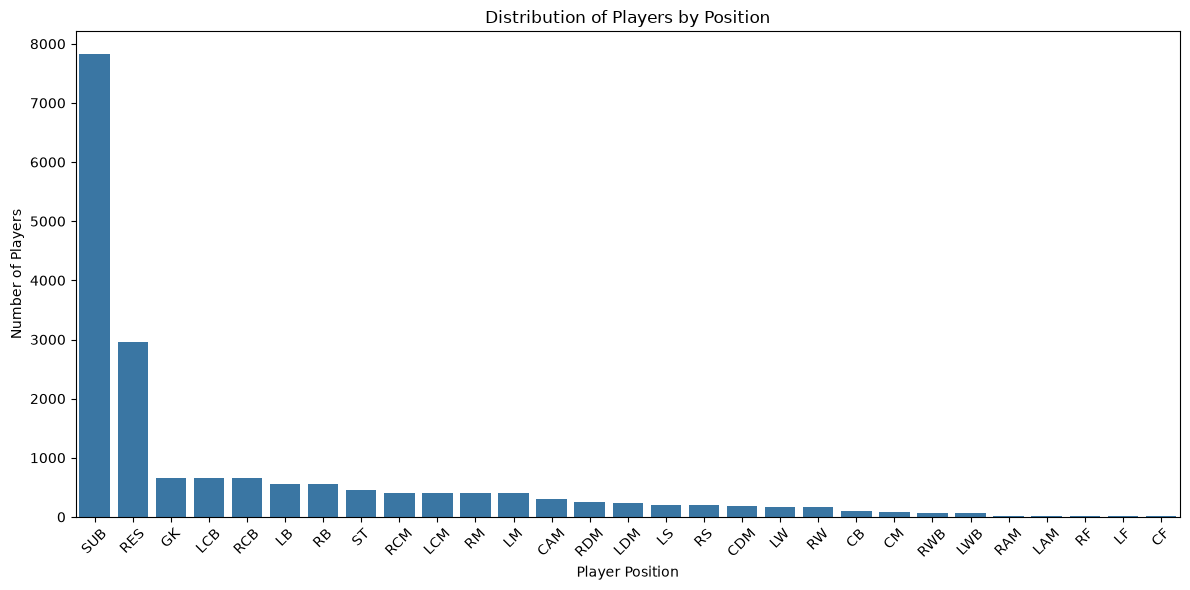

In [21]:
plt.figure(figsize=(12, 6))

sns.countplot(
    color="#2878B5",
    data=fifa,
    x='team_position',
    order=fifa['team_position'].value_counts().index
)

plt.title('Distribution of Players by Position')
plt.xlabel('Player Position')
plt.ylabel('Number of Players')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Observations – Player Position Distribution

The analysis reveals an uneven distribution of players across team positions.

- **Substitutes (SUB):** Represent the largest category with 7,820 players.
- **Reserves (RES):** Account for 2,958 players, forming the second-largest category.
- **Goalkeepers (GK):** Include 662 players.
- **Defensive Positions:** LCB and RCB each contain 660 players.
- **Centre Forward (CF):** Has the lowest representation with only 14 players.

**Conclusion:** The dataset contains a large proportion of substitute and reserve players compared with players assigned to specific starting positions. Therefore, team position distribution should be interpreted while considering the distinction between starting positions and squad status.

In [22]:

# ============================================
# 4.3 POSITION-WISE PLAYER PERFORMANCE ANALYSIS
# STEP 1: POSITION DISTRIBUTION
# ============================================

print("PLAYER POSITION DISTRIBUTION")

position_counts = fifa['team_position'].value_counts(dropna=False)

display(position_counts.to_frame(name='Player_Count'))

print("\nUnique Team Positions:")
print(fifa['team_position'].unique())


PLAYER POSITION DISTRIBUTION


,Player_Count
team_position,
SUB,7820
RES,2958
GK,662
LCB,660
RCB,660
LB,560
RB,560
ST,458
RCM,411



Unique Team Positions:
<StringArray>
[ 'RW',  'LW', 'CAM',  'GK', 'RCM', 'LCB',  'ST', 'CDM', 'LDM',  'RM', 'RCB',
 'LCM',  'LM',  'CF', 'SUB',  'LB',  'LS',  'RB', 'RDM', 'RES', 'RAM',  'RS',
  'RF',  'CM',  'CB',  'LF', 'LAM',   nan, 'RWB', 'LWB']
Length: 30, dtype: str


In [23]:

# ============================================
# 4.3 POSITION-WISE PLAYER PERFORMANCE ANALYSIS
# STEP 2: AVERAGE OVERALL RATING BY POSITION
# ============================================

import pandas as pd
import matplotlib.pyplot as plt

# Remove substitutes, reserves and missing positions
position_data = fifa[
    ~fifa['team_position'].isin(['SUB', 'RES'])
].copy()

position_data = position_data.dropna(
    subset=['team_position', 'overall']
)

# Calculate position-wise performance
position_performance = (
    position_data
    .groupby('team_position')
    .agg(
        Player_Count=('overall', 'count'),
        Average_Overall=('overall', 'mean'),
        Highest_Overall=('overall', 'max'),
        Lowest_Overall=('overall', 'min')
    )
    .sort_values(
        by='Average_Overall',
        ascending=False
    )
)

# Display results
print("POSITION-WISE PLAYER PERFORMANCE")

display(position_performance.round(2))

print("\nTotal Positions Analyzed:",
      len(position_performance))

print("Total Players Analyzed:",
      position_performance['Player_Count'].sum())

print("\nHighest Average Rated Position:")
display(position_performance.head(1).round(2))

print("\nPosition-wise performance analysis completed successfully.")


POSITION-WISE PLAYER PERFORMANCE


,Player_Count,Average_Overall,Highest_Overall,Lowest_Overall
team_position,,,,
CF,14,75.21,87,65
LAM,23,71.61,82,62
LF,19,71.00,82,63
RAM,23,70.83,85,56
ST,458,70.40,89,50
RW,161,70.34,94,52
CAM,311,70.34,92,53
CDM,181,70.30,89,52
LW,162,70.19,93,54



Total Positions Analyzed: 27
Total Players Analyzed: 7260

Highest Average Rated Position:


,Player_Count,Average_Overall,Highest_Overall,Lowest_Overall
team_position,,,,
CF,14,75.21,87,65



Position-wise performance analysis completed successfully.


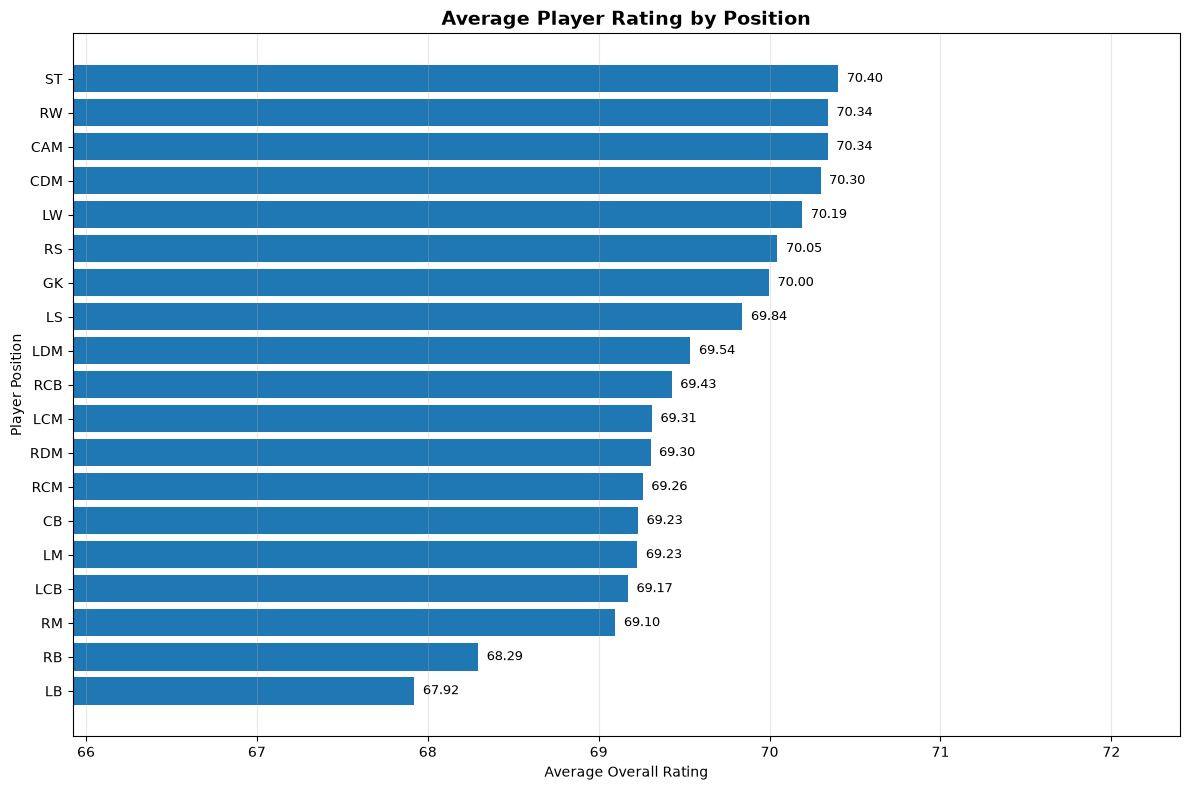

Position-wise performance visualization completed successfully.


In [24]:

# ============================================
# 4.3 POSITION-WISE PERFORMANCE VISUALIZATION
# ============================================

import matplotlib.pyplot as plt
import numpy as np

# Filter positions with at least 100 players
plot_data = position_performance[
    position_performance['Player_Count'] >= 100
].sort_values(
    by='Average_Overall',
    ascending=True
)

plt.figure(figsize=(12, 8))

bars = plt.barh(
    plot_data.index,
    plot_data['Average_Overall']
)

# Add average rating labels
for bar, value in zip(
    bars,
    plot_data['Average_Overall']
):
    plt.text(
        value + 0.05,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.2f}',
        va='center',
        fontsize=9
    )

plt.xlabel('Average Overall Rating')
plt.ylabel('Player Position')

plt.title(
    'Average Player Rating by Position',
    fontsize=14,
    fontweight='bold'
)

plt.xlim(
    plot_data['Average_Overall'].min() - 2,
    plot_data['Average_Overall'].max() + 2
)

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print("Position-wise performance visualization completed successfully.")



### Interpretation

- Centre Forward (CF) recorded the highest average overall rating of 75.21, although this position contains only 14 players.
- Among positions with at least 100 players, Strikers (ST) recorded the highest average rating of 70.40.
- Goalkeepers (GK) and central attacking midfielders (CAM) also demonstrated relatively strong average ratings.
- Left Wing Back (LWB) recorded the lowest average rating among the analyzed positions.
- Differences in player counts should be considered when comparing average ratings across positions.

### Business Insight

Football clubs can use position-wise performance analysis to evaluate player strengths and identify potential recruitment opportunities. Comparing average ratings alongside player counts helps scouting teams make more informed decisions about squad composition and position-specific recruitment.



## 4.4 Player Market Value Analysis

### Objective

To analyze the relationship between football players'
overall ratings and their estimated market values.

This analysis helps identify how player performance
relates to market valuation and supports data-driven
recruitment and investment decisions.


TOTAL PLAYERS ANALYZED: 18028
Overall Rating vs Market Value Correlation: 0.646


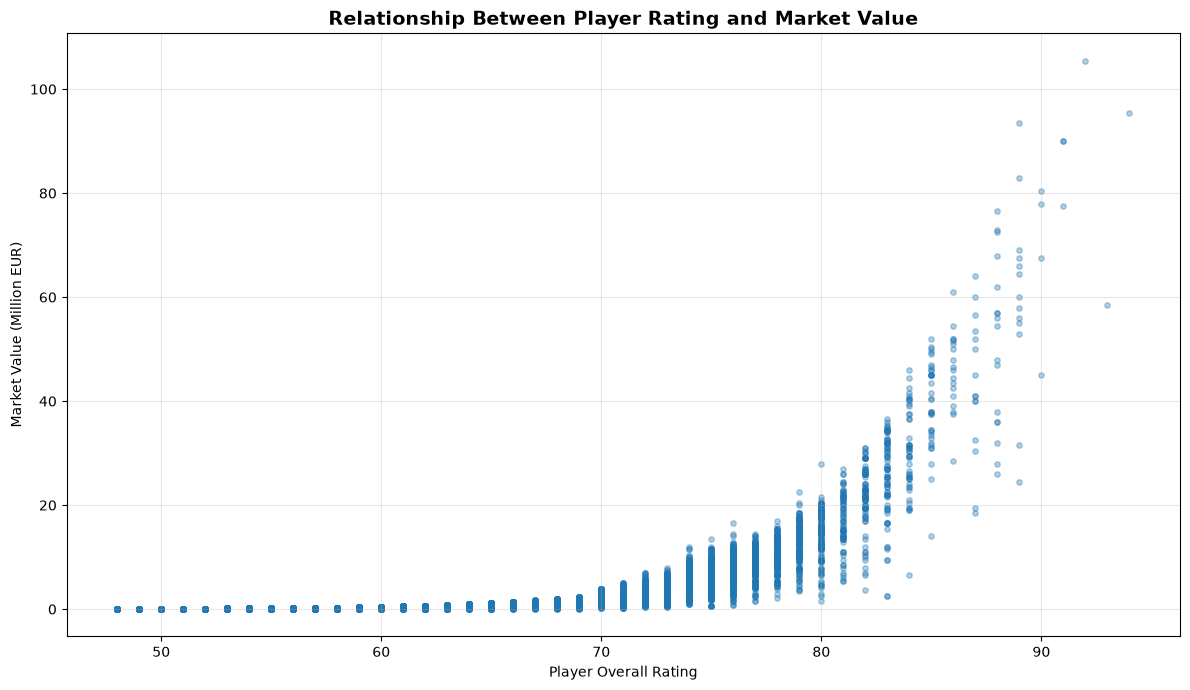

Player market value analysis completed successfully.


In [25]:

# ============================================
# 4.4 PLAYER MARKET VALUE ANALYSIS
# ============================================

import pandas as pd
import matplotlib.pyplot as plt

# Select required columns
market_data = fifa[
    ['overall', 'value_eur', 'age']
].copy()

# Convert columns to numeric
for col in ['overall', 'value_eur', 'age']:
    market_data[col] = pd.to_numeric(
        market_data[col], errors='coerce'
    )

# Remove missing and invalid values
market_data = market_data.dropna()
market_data = market_data[
    market_data['value_eur'] > 0
]

# Convert market value into millions
market_data['Value_Million_EUR'] = (
    market_data['value_eur'] / 1_000_000
)

print("TOTAL PLAYERS ANALYZED:", len(market_data))

# Correlation analysis
correlation = market_data[
    ['overall', 'Value_Million_EUR']
].corr().iloc[0, 1]

print(
    f"Overall Rating vs Market Value Correlation: "
    f"{correlation:.3f}"
)

# Scatter plot
plt.figure(figsize=(12, 7))

plt.scatter(
    market_data['overall'],
    market_data['Value_Million_EUR'],
    alpha=0.35,
    s=15
)

plt.xlabel('Player Overall Rating')
plt.ylabel('Market Value (Million EUR)')

plt.title(
    'Relationship Between Player Rating and Market Value',
    fontsize=14,
    fontweight='bold'
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Player market value analysis completed successfully.")



### Interpretation

- The analysis covered 18,028 football players.
- The correlation coefficient between overall rating and market value is 0.646, indicating a moderately strong positive relationship.
- Players with higher overall ratings generally tend to have higher market values.
- Market values show greater variation among highly rated players.
- Players with similar overall ratings may have different market values due to other influencing factors.

### Business Insight

Football clubs and recruitment teams can use this analysis to understand the relationship between player performance and market valuation. This can support recruitment planning, player evaluation, and investment decisions. However, market value should not be determined using overall rating alone, as age, potential, and other player characteristics may also influence valuation.



## 4.5 Age vs Market Value Analysis

### Objective

To analyze the relationship between player age and
market value and identify how player valuations
differ across age groups.

This analysis helps football clubs understand
player valuation patterns and identify potential
recruitment and investment opportunities.


AGE-WISE MARKET VALUE ANALYSIS


,Player_Count,Average_Value,Median_Value
age,,,
17,229,0.30,0.15
18,639,0.52,0.20
19,1010,0.88,0.32
20,1244,1.23,0.45
21,1371,1.66,0.57
22,1442,2.19,0.68
23,1347,2.67,0.78
24,1287,3.07,0.90
25,1307,3.36,0.95


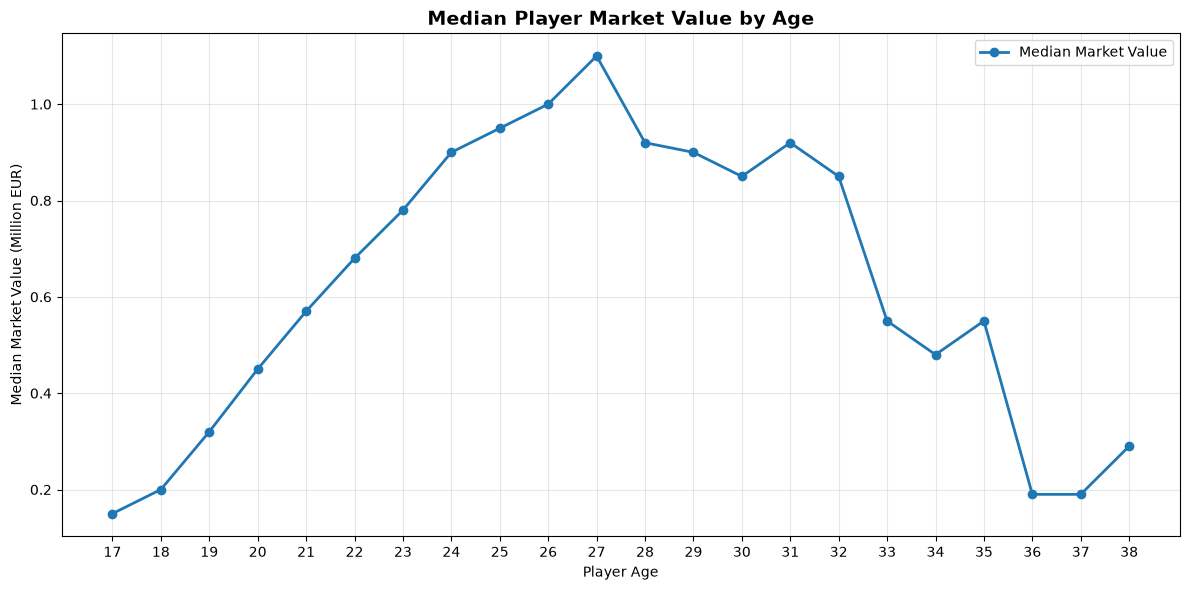


Age with highest median market value: 27
Median market value: 1.1 Million EUR
Age-wise market value analysis completed successfully.


In [26]:


# ============================================
# 4.5 AGE VS MARKET VALUE ANALYSIS
# ============================================

import pandas as pd
import matplotlib.pyplot as plt

# Prepare analysis dataset
age_market = fifa[
    ['age', 'value_eur']
].copy()

# Convert columns to numeric
age_market['age'] = pd.to_numeric(
    age_market['age'], errors='coerce'
)

age_market['value_eur'] = pd.to_numeric(
    age_market['value_eur'], errors='coerce'
)

# Remove missing and invalid values
age_market = age_market.dropna()

age_market = age_market[
    age_market['value_eur'] > 0
]

# Convert market value into millions
age_market['Value_Million_EUR'] = (
    age_market['value_eur'] / 1_000_000
)

# Calculate age-wise statistics
age_analysis = age_market.groupby('age').agg(
    Player_Count=('value_eur', 'count'),
    Average_Value=('Value_Million_EUR', 'mean'),
    Median_Value=('Value_Million_EUR', 'median')
).round(2)

# Filter age groups with at least 30 players
age_analysis_filtered = age_analysis[
    age_analysis['Player_Count'] >= 30
]

print("AGE-WISE MARKET VALUE ANALYSIS")

display(age_analysis_filtered)

# Visualize median market value by age
plt.figure(figsize=(12, 6))

plt.plot(
    age_analysis_filtered.index,
    age_analysis_filtered['Median_Value'],
    marker='o',
    linewidth=2,
    label='Median Market Value'
)

plt.xlabel('Player Age')
plt.ylabel('Median Market Value (Million EUR)')

plt.title(
    'Median Player Market Value by Age',
    fontsize=14,
    fontweight='bold'
)

plt.xticks(age_analysis_filtered.index)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Identify age with highest median market value
highest_age = age_analysis_filtered[
    'Median_Value'
].idxmax()

print("\nAge with highest median market value:", highest_age)

print(
    "Median market value:",
    age_analysis_filtered.loc[
        highest_age, 'Median_Value'
    ],
    "Million EUR"
)

print(
    "Age-wise market value analysis completed successfully."
)



### Interpretation

- The analysis shows that player market value generally increases from age 17 to age 27.
- Players aged 27 have the highest median market value of €1.10 million.
- The median market value increases steadily during the early stages of a player's career.
- After age 27, median market value generally starts declining.
- Players aged 28–32 maintain relatively higher market values compared to older age groups.
- The decline becomes more noticeable after age 32.
- Older age groups have fewer players, so their results should be interpreted cautiously.

### Business Insight

Football clubs and recruitment teams can use age-wise market value analysis to identify suitable investment opportunities. Players around 23–28 years may offer a balance between current performance and future potential. Younger players can represent long-term investment opportunities, while experienced players may provide immediate squad value. Clubs should consider performance, potential, position, and experience alongside age when making recruitment and transfer decisions.



## 4.6 Club-wise Player Performance and Market Value Analysis

### Objective

To analyze football clubs based on player count, average overall rating, and total market value.

This analysis helps identify clubs with strong squads and higher player market valuations.


TOP 10 CLUBS BY TOTAL MARKET VALUE


,club,Player_Count,Average_Overall,Total_Market_Value,Average_Market_Value
505,Real Madrid,33,80.12,897850000,27207575.76
224,FC Barcelona,33,78.36,869300000,26342424.24
400,Manchester City,33,77.00,845745000,25628636.36
350,Juventus,33,80.06,735475000,22287121.21
389,Liverpool,33,75.85,693265000,21008030.30
226,FC Bayern München,23,81.30,688775000,29946739.13
462,Paris Saint-Germain,33,75.91,687550000,20834848.48
626,Tottenham Hotspur,33,76.48,649850000,19692424.24
63,Atlético Madrid,33,76.18,590375000,17890151.52
92,Borussia Dortmund,31,75.32,532325000,17171774.19


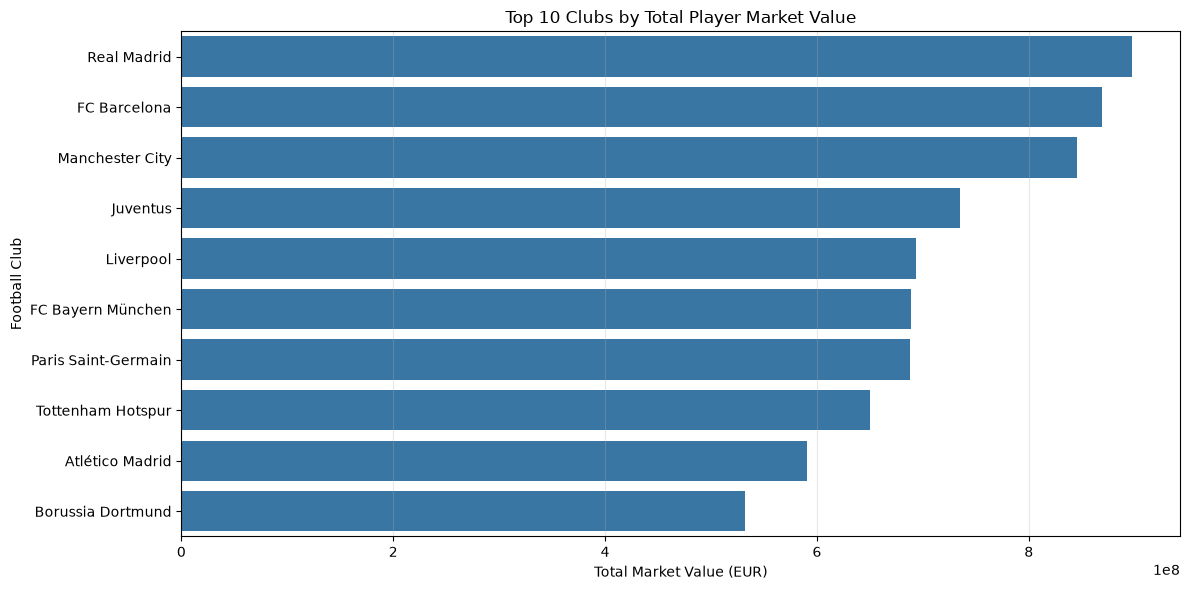

Club-wise player performance analysis completed successfully.


In [27]:

# ============================================
# 4.6 CLUB-WISE PLAYER PERFORMANCE ANALYSIS
# ============================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare club-wise analysis
club_analysis = fifa.groupby('club').agg(
    Player_Count=('sofifa_id', 'count'),
    Average_Overall=('overall', 'mean'),
    Total_Market_Value=('value_eur', 'sum'),
    Average_Market_Value=('value_eur', 'mean')
).reset_index()

# Remove missing club names
club_analysis = club_analysis.dropna(subset=['club'])

# Sort by total market value
club_analysis = club_analysis.sort_values(
    by='Total_Market_Value',
    ascending=False
)

print("TOP 10 CLUBS BY TOTAL MARKET VALUE")
display(club_analysis.head(10).round(2))

# Visualization
top_10_clubs = club_analysis.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    color="#2878B5",
    data=top_10_clubs,
    x='Total_Market_Value',
    y='club'
)

plt.title('Top 10 Clubs by Total Player Market Value')
plt.xlabel('Total Market Value (EUR)')
plt.ylabel('Football Club')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print("Club-wise player performance analysis completed successfully.")



### Interpretation

- Real Madrid has the highest total player market value at approximately €897.85 million.
- FC Barcelona ranks second with approximately €869.30 million.
- Manchester City ranks third with approximately €845.75 million.
- Juventus and Liverpool also demonstrate high total squad market values.
- FC Bayern München has the highest average overall rating of 81.30 among the top 10 clubs.
- FC Bayern München also has the highest average player market value of approximately €29.95 million.
- Most clubs in the top 10 have 33 players, while Bayern München has 23 players.
- Total squad market value depends on both the number of players and their individual market valuations.

### Business Insight

Football clubs can use club-wise performance and market value analysis to benchmark their squad strength and financial value. Real Madrid leads in total squad market value, while Bayern München demonstrates a higher average player rating and average market value despite having fewer players. Recruitment teams can use these insights to identify valuable squads, evaluate transfer investments, and compare player quality across competing clubs.



## 4.7 Club-wise Player Rating Comparison

### Objective

To compare football clubs based on their average player overall ratings and identify clubs with the strongest squad performance.

This analysis helps evaluate squad quality independently of total market value.


TOP 10 CLUBS BY AVERAGE PLAYER RATING


,club,Player_Count,Average_Overall,Highest_Overall
226,FC Bayern München,23,81.30,89
505,Real Madrid,33,80.12,91
350,Juventus,33,80.06,93
650,Uruguay,23,78.61,82
224,FC Barcelona,33,78.36,94
77,Bayer 04 Leverkusen,25,77.28,84
141,Chelsea,33,77.06,89
400,Manchester City,33,77.00,91
425,Napoli,31,76.87,89
401,Manchester United,33,76.85,89


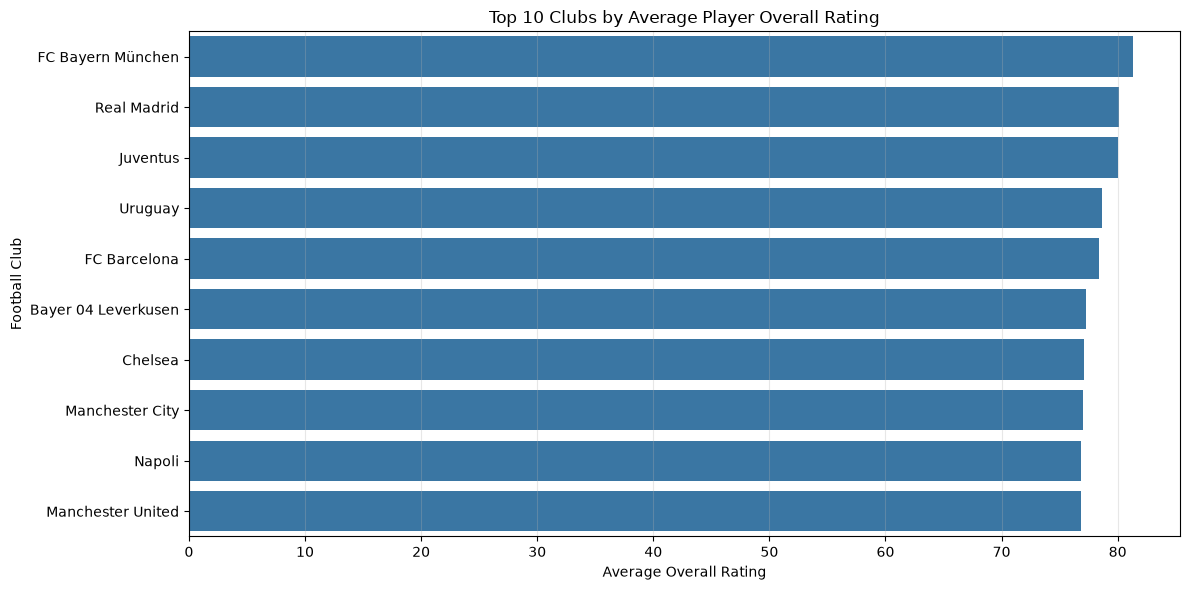

Club-wise player rating comparison completed successfully.


In [28]:

# ============================================
# 4.7 CLUB-WISE PLAYER RATING COMPARISON
# ============================================

# Calculate club-wise player ratings
club_rating = fifa.groupby('club').agg(
    Player_Count=('sofifa_id', 'count'),
    Average_Overall=('overall', 'mean'),
    Highest_Overall=('overall', 'max')
).reset_index()

# Remove missing club names
club_rating = club_rating.dropna(subset=['club'])

# Consider clubs with at least 15 players
club_rating = club_rating[
    club_rating['Player_Count'] >= 15
]

# Sort by average overall rating
club_rating = club_rating.sort_values(
    by='Average_Overall',
    ascending=False
)

print("TOP 10 CLUBS BY AVERAGE PLAYER RATING")

display(club_rating.head(10).round(2))

# Visualization
top_clubs_rating = club_rating.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    color="#2878B5",
    data=top_clubs_rating,
    x='Average_Overall',
    y='club'
)

plt.title('Top 10 Clubs by Average Player Overall Rating')
plt.xlabel('Average Overall Rating')
plt.ylabel('Football Club')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print("Club-wise player rating comparison completed successfully.")



### Interpretation

- FC Bayern München ranks first with the highest average overall player rating of 81.30 across 23 players.
- Real Madrid ranks second with an average overall rating of 80.12 across 33 players.
- Juventus ranks third with an average overall rating of 80.06 across 33 players.
- Uruguay appears among the top teams with an average rating of 78.61 across 23 players.
- FC Barcelona ranks fifth with an average overall rating of 78.36.
- The top 10 teams demonstrate consistently strong average player ratings.
- FC Barcelona has the highest individual player rating of 94 among the teams shown.
- Squad size does not necessarily determine average player quality.

### Business Insight

Football clubs can use club-wise player rating analysis to benchmark squad quality and identify teams with strong player performance. FC Bayern München leads in average player ratings, while Real Madrid and Juventus also demonstrate strong squad quality. These insights can support recruitment planning, squad evaluation, player scouting, and strategic team development. However, clubs should consider squad size, player positions, and individual performance when making recruitment decisions.


## 4.8 — Nationality-wise Player Performance Analysis
### Objective:  
Analyze player distribution and performance across different nationalities to identify countries producing highly rated football players.

In [29]:

# ============================================
# 4.8 NATIONALITY-WISE PLAYER PERFORMANCE ANALYSIS
# STEP 1: PLAYER COUNT BY NATIONALITY
# ============================================

# Count players by nationality
nationality_counts = (
    fifa['nationality']
    .value_counts()
    .reset_index()
)

nationality_counts.columns = ['Nationality', 'Player_Count']

# Display top 15 nationalities
print("TOP 15 NATIONALITIES BY PLAYER COUNT")

display(nationality_counts.head(15))

# Total unique nationalities
print("\nTotal Unique Nationalities:", fifa['nationality'].nunique())

# Total players analyzed
print("Total Players Analyzed:", fifa['nationality'].count())

print("\nNationality-wise player count analysis completed successfully.")


TOP 15 NATIONALITIES BY PLAYER COUNT


,Nationality,Player_Count
0,England,1667
1,Germany,1216
2,Spain,1035
3,France,984
4,Argentina,886
5,Brazil,824
6,Italy,732
7,Colombia,591
8,Japan,453
9,Netherlands,416



Total Unique Nationalities: 162
Total Players Analyzed: 18278

Nationality-wise player count analysis completed successfully.


### Average Overall Rating by Nationality

In [30]:

# ============================================
# STEP 2: AVERAGE OVERALL RATING BY NATIONALITY
# ============================================

# Group players by nationality
nationality_performance = (
    fifa.groupby('nationality')
    .agg(
        Player_Count=('overall', 'count'),
        Average_Overall=('overall', 'mean'),
        Highest_Overall=('overall', 'max'),
        Lowest_Overall=('overall', 'min')
    )
    .reset_index()
)

# Filter nationalities with at least 30 players
nationality_performance = nationality_performance[
    nationality_performance['Player_Count'] >= 30
]

# Sort by average overall rating
nationality_performance = nationality_performance.sort_values(
    by='Average_Overall',
    ascending=False
)

# Display top 15 nationalities
print("TOP 15 NATIONALITIES BY AVERAGE PLAYER RATING")

display(nationality_performance.head(15).round(2))

# Display total nationalities analyzed
print("\nTotal Nationalities Analyzed:",
      nationality_performance.shape[0])

print("\nNationality-wise performance analysis completed successfully.")


TOP 15 NATIONALITIES BY AVERAGE PLAYER RATING


,nationality,Player_Count,Average_Overall,Highest_Overall,Lowest_Overall
155,Uruguay,164,71.65,89,53
2,Algeria,50,71.38,84,59
18,Brazil,824,71.16,92,52
121,Portugal,344,70.51,93,52
42,Ecuador,53,70.49,81,59
38,Czech Republic,102,70.31,84,58
43,Egypt,30,70.10,90,60
136,Spain,1035,69.95,89,52
152,Ukraine,69,69.87,82,53
117,Paraguay,80,69.79,80,59



Total Nationalities Analyzed: 68

Nationality-wise performance analysis completed successfully.


### Visualization

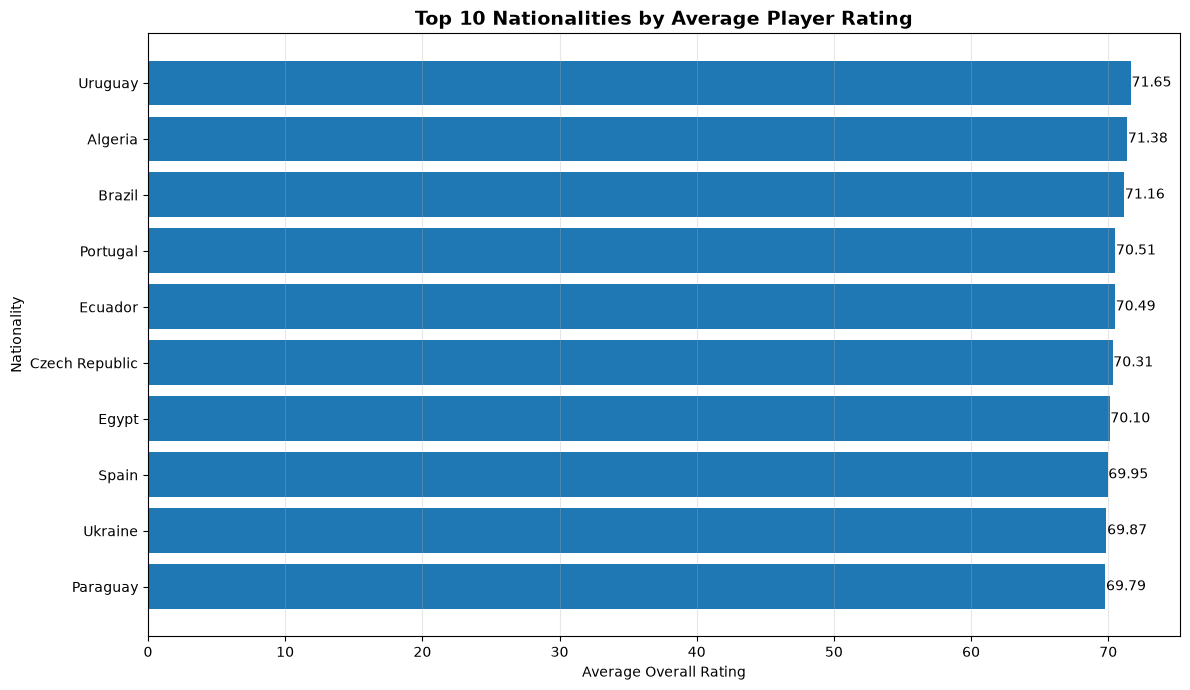

Nationality-wise performance visualization completed successfully.


In [31]:

# ============================================
# STEP 3: NATIONALITY-WISE PERFORMANCE VISUALIZATION
# ============================================

import matplotlib.pyplot as plt

# Select top 10 nationalities
top_10_nationalities = nationality_performance.head(10)

# Create visualization
plt.figure(figsize=(12, 7))

plt.barh(
    top_10_nationalities['nationality'],
    top_10_nationalities['Average_Overall']
)

# Add value labels
for index, value in enumerate(top_10_nationalities['Average_Overall']):
    plt.text(value + 0.05, index, f'{value:.2f}', va='center')

plt.title('Top 10 Nationalities by Average Player Rating',
          fontsize=14, fontweight='bold')

plt.xlabel('Average Overall Rating')
plt.ylabel('Nationality')

plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

print("Nationality-wise performance visualization completed successfully.")



### Interpretation

- Uruguay has the highest average overall player rating of 71.65 among the analyzed nationalities.
- Algeria ranks second with an average rating of 71.38.
- Brazil ranks third with an average rating of 71.16 across 824 players.
- Portugal and Ecuador follow with average ratings of 70.51 and 70.49 respectively.
- Spain has the largest player representation among the top 10 nationalities, with 1,035 players.
- All top 10 nationalities have average overall ratings above 69.
- Uruguay demonstrates strong average player performance with a substantial sample of 164 players.
- The results indicate differences in average player ratings across nationalities.

### Business Insight

Football clubs and recruitment agencies can use nationality-wise performance analysis to identify countries with strong player talent. Uruguay, Algeria, and Brazil demonstrate the highest average player ratings in this analysis. Brazil and Spain also have substantial player representation, providing a larger talent pool for scouting. These insights can support international scouting, recruitment planning, and talent identification. However, clubs should also consider player positions, individual abilities, market values, and recruitment budgets before making decisions.


## 4.9 — Nationality-wise Market Value Analysis
### Objective:
Identify which nationalities have the highest player market values and compare their financial contribution.

In [32]:

# ============================================
# 4.9 NATIONALITY-WISE MARKET VALUE ANALYSIS
# ============================================

nationality_market_value = (
    fifa.groupby('nationality')
    .agg(
        Player_Count=('value_eur', 'count'),
        Total_Market_Value=('value_eur', 'sum'),
        Average_Market_Value=('value_eur', 'mean'),
        Median_Market_Value=('value_eur', 'median')
    )
    .reset_index()
)

# Filter nationalities with at least 30 players
nationality_market_value = nationality_market_value[
    nationality_market_value['Player_Count'] >= 30
]

# Sort by total market value
nationality_market_value = nationality_market_value.sort_values(
    by='Total_Market_Value',
    ascending=False
)

# Display top 15 nationalities
print("TOP 15 NATIONALITIES BY TOTAL MARKET VALUE")

display(nationality_market_value.head(15).round(2))

print("\nTotal Nationalities Analyzed:",
      nationality_market_value.shape[0])

print("\nTotal Market Value:",
      round(nationality_market_value['Total_Market_Value'].sum(), 2))

print("\nNationality-wise market value analysis completed successfully.")


TOP 15 NATIONALITIES BY TOTAL MARKET VALUE


,nationality,Player_Count,Total_Market_Value,Average_Market_Value,Median_Market_Value
136,Spain,1035,4735490000,4575352.66,1400000.0
18,Brazil,824,3728055000,4524338.59,1750000.0
53,France,984,3696205000,3756305.89,850000.0
57,Germany,1216,3103520000,2552236.84,700000.0
5,Argentina,886,3026500000,3415914.22,1400000.0
45,England,1667,2695050000,1616706.66,450000.0
77,Italy,732,2154825000,2943750.00,925000.0
121,Portugal,344,1682470000,4890901.16,1800000.0
108,Netherlands,416,1430265000,3438137.02,1000000.0
12,Belgium,268,1236365000,4613302.24,1000000.0



Total Nationalities Analyzed: 68

Total Market Value: 44169150000

Nationality-wise market value analysis completed successfully.


## Visualization: Top 10 Nationalities by Market Value

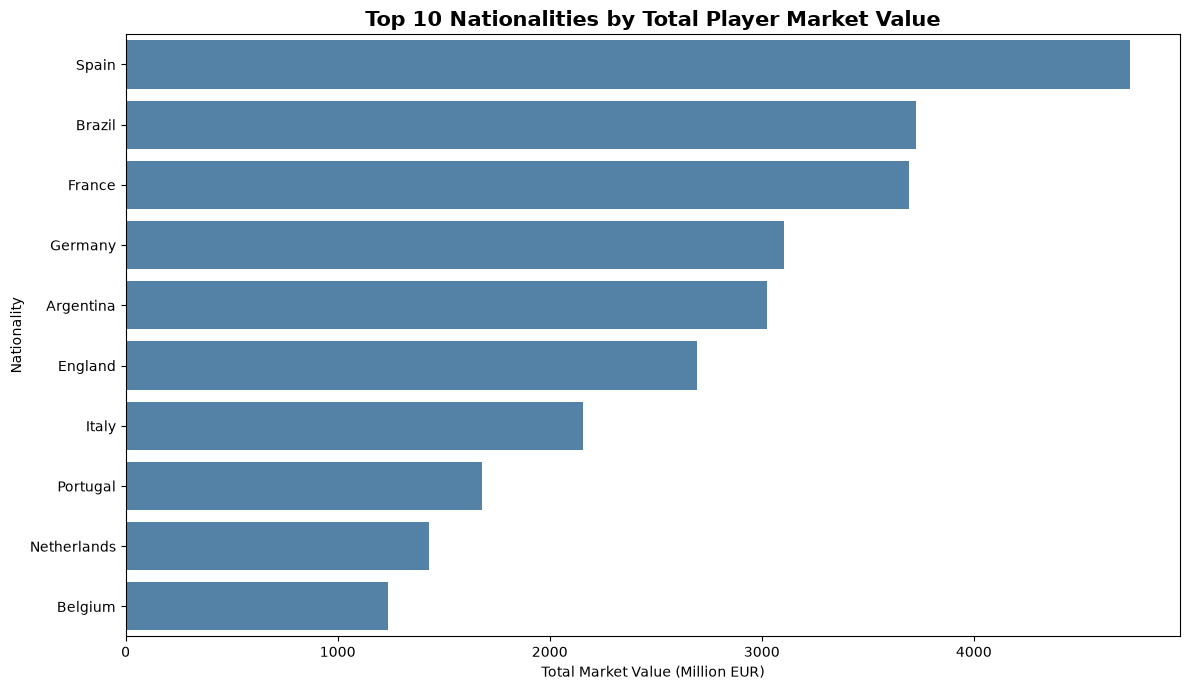

Nationality-wise market value visualization completed successfully.


In [33]:

# ============================================
# TOP 10 NATIONALITIES BY TOTAL MARKET VALUE
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

top_nationalities = nationality_market_value.head(10).copy()

# Convert market value into millions
top_nationalities['Market_Value_Millions'] = (
    top_nationalities['Total_Market_Value'] / 1_000_000
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_nationalities,
    x='Market_Value_Millions',
    y='nationality',
    color='steelblue'
)

plt.title(
    'Top 10 Nationalities by Total Player Market Value',
    fontsize=15,
    fontweight='bold'
)
plt.xlabel('Total Market Value (Million EUR)')
plt.ylabel('Nationality')

plt.tight_layout()
plt.show()

print("Nationality-wise market value visualization completed successfully.")


### Interpretation

- Spain has the highest total player market value, approximately €4,735.49 million.
- Brazil ranks second with approximately €3,728.06 million.
- France ranks third with approximately €3,696.21 million.
- Germany and Argentina also demonstrate substantial combined player market values.
- England has the largest player representation among the analyzed nationalities, with 1,667 players.
- Spain, Brazil, and France have strong combined market valuations.
- Total market value is influenced by both the number of players and their individual market valuations.
- Nationalities with fewer players can still demonstrate high average player market values.

### Business Insight

Football clubs and recruitment agencies can use nationality-wise market value analysis to identify countries with strong football talent and potential recruitment opportunities. Spain, Brazil, and France demonstrate the highest combined player market values in this analysis. These insights can help clubs evaluate international recruitment markets, plan transfer budgets, and identify potential investment opportunities. However, recruitment decisions should also consider individual player performance, age, position, and development potential rather than relying solely on nationality-wise market value.

## Nationality-wise Player Age Analysis
### Objective: 
Understand how player age varies across different nationalities and identify countries with younger and more experienced player populations.

In [34]:

# ============================================
# NATIONALITY-WISE PLAYER AGE ANALYSIS
# ============================================

# Group players by nationality
nationality_age = (
    fifa.groupby('nationality')
    .agg(
        Player_Count=('age', 'count'),
        Average_Age=('age', 'mean'),
        Median_Age=('age', 'median'),
        Minimum_Age=('age', 'min'),
        Maximum_Age=('age', 'max')
    )
    .reset_index()
)

# Consider nationalities with at least 30 players
nationality_age = nationality_age[
    nationality_age['Player_Count'] >= 30
]

# Sort by average age
nationality_age = nationality_age.sort_values(
    by='Average_Age',
    ascending=True
)

# Display youngest 15 nationalities
print("15 NATIONALITIES WITH LOWEST AVERAGE PLAYER AGE")

display(nationality_age.head(15).round(2))

print("\nTotal Nationalities Analyzed:",
      nationality_age.shape[0])

print("\nTotal Players Analyzed:",
      nationality_age['Player_Count'].sum())

print("\nNationality-wise player age analysis completed successfully.")


15 NATIONALITIES WITH LOWEST AVERAGE PLAYER AGE


,nationality,Player_Count,Average_Age,Median_Age,Minimum_Age,Maximum_Age
97,Mali,55,23.45,23.0,18,33
112,Nigeria,126,23.73,23.0,18,33
86,Kosovo,40,23.75,24.0,17,35
58,Ghana,130,23.86,23.0,17,33
45,England,1667,24.07,23.0,16,40
12,Belgium,268,24.23,24.0,17,40
108,Netherlands,416,24.26,24.0,17,36
40,Denmark,345,24.29,24.0,16,37
7,Australia,196,24.33,24.0,17,37
53,France,984,24.35,24.0,16,39



Total Nationalities Analyzed: 68

Total Players Analyzed: 17622

Nationality-wise player age analysis completed successfully.


## Visualization: Top 10 Youngest Nationalities


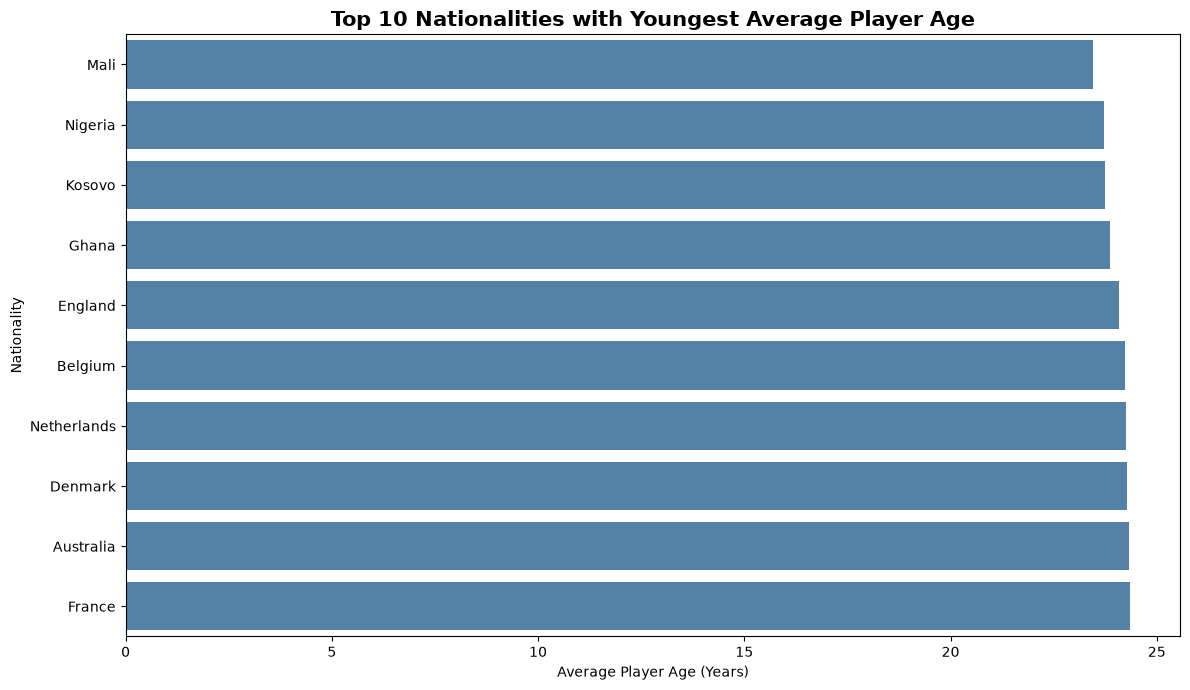

Youngest nationality visualization completed successfully.


In [35]:

# ============================================
# TOP 10 YOUNGEST NATIONALITIES
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

youngest_nationalities = nationality_age.head(10).copy()

plt.figure(figsize=(12, 7))

sns.barplot(
    data=youngest_nationalities,
    x='Average_Age',
    y='nationality',
    color='steelblue'
)

plt.title(
    'Top 10 Nationalities with Youngest Average Player Age',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Average Player Age (Years)')
plt.ylabel('Nationality')

plt.tight_layout()
plt.show()

print("Youngest nationality visualization completed successfully.")


## Compare youngest and oldest nationalities

In [36]:

# ============================================
# YOUNGEST VS OLDEST NATIONALITIES
# ============================================

youngest_10 = nationality_age.nsmallest(10, 'Average_Age').copy()

oldest_10 = nationality_age.nlargest(10, 'Average_Age').copy()

print("TOP 10 YOUNGEST NATIONALITIES")
display(youngest_10.round(2))

print("\nTOP 10 OLDEST NATIONALITIES")
display(oldest_10.round(2))


TOP 10 YOUNGEST NATIONALITIES


,nationality,Player_Count,Average_Age,Median_Age,Minimum_Age,Maximum_Age
97,Mali,55,23.45,23.0,18,33
112,Nigeria,126,23.73,23.0,18,33
86,Kosovo,40,23.75,24.0,17,35
58,Ghana,130,23.86,23.0,17,33
45,England,1667,24.07,23.0,16,40
12,Belgium,268,24.23,24.0,17,40
108,Netherlands,416,24.26,24.0,17,36
40,Denmark,345,24.29,24.0,16,37
7,Australia,196,24.33,24.0,17,37
53,France,984,24.35,24.0,16,39



TOP 10 OLDEST NATIONALITIES


,nationality,Player_Count,Average_Age,Median_Age,Minimum_Age,Maximum_Age
18,Brazil,824,28.03,27.0,18,41
42,Ecuador,53,27.92,28.0,18,38
155,Uruguay,164,27.49,27.0,19,38
43,Egypt,30,27.40,27.0,20,34
134,South Africa,72,26.99,27.5,18,35
19,Bulgaria,41,26.85,27.0,17,37
2,Algeria,50,26.84,27.0,18,33
38,Czech Republic,102,26.79,27.0,16,38
28,China PR,373,26.61,26.0,17,40
117,Paraguay,80,26.52,26.0,18,36


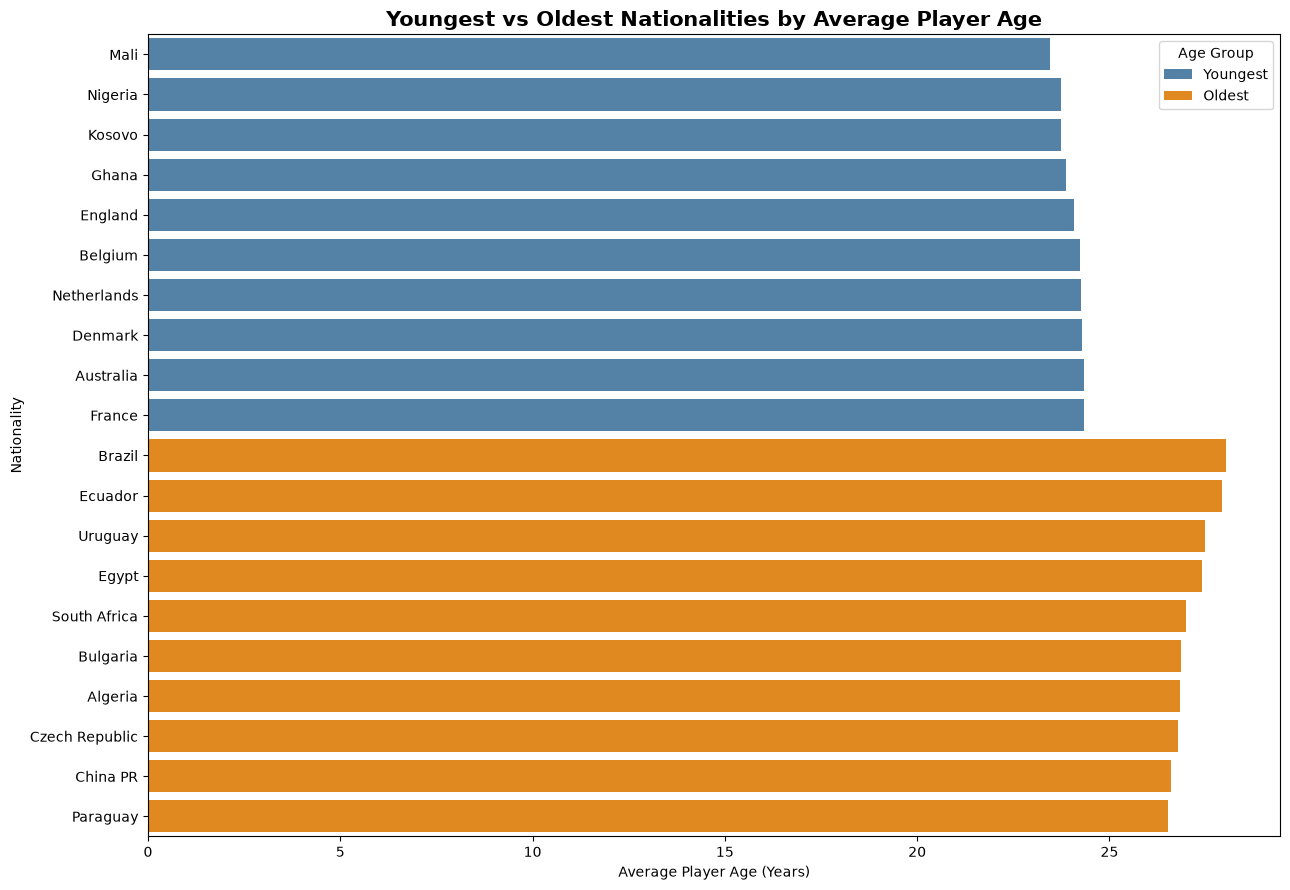

Nationality age comparison visualization completed successfully.


In [37]:

# ============================================
# YOUNGEST VS OLDEST NATIONALITIES VISUALIZATION
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

youngest_10['Age_Group'] = 'Youngest'
oldest_10['Age_Group'] = 'Oldest'

age_comparison = __import__('pandas').concat(
    [youngest_10, oldest_10]
)

plt.figure(figsize=(13, 9))

sns.barplot(
    color="#2878B5",
    data=age_comparison,
    x='Average_Age',
    y='nationality',
    hue='Age_Group',
    palette=['steelblue', 'darkorange']
)

plt.title(
    'Youngest vs Oldest Nationalities by Average Player Age',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Average Player Age (Years)')
plt.ylabel('Nationality')
plt.legend(title='Age Group')
plt.tight_layout()
plt.show()

print("Nationality age comparison visualization completed successfully.")


# TASK 2 — FOOTBALL SKILLS AND PLAYER CLUSTERING

Explore football skills and cluster players based on their attributes. This task includes feature selection, standardization, cluster-number evaluation, K-Means clustering, cluster comparison, profiling, and interpretation.

## Phase 2 – Skill-Based Player Clustering

### 2.1 Identification of Player Skill Features

This section identifies relevant technical skill attributes for grouping players based on their playing abilities.

In [38]:
# Identify skill-related numerical features
skill_features = [
    col for col in fifa.select_dtypes(include='number').columns
    if col.startswith(('skill_', 'attacking_'))
]

# Display identified features
print("Total Skill Features:", len(skill_features))

print("\nIdentified Skill Features:")
for feature in skill_features:
    print(feature)

# Check missing values
skill_missing_summary = pd.DataFrame({
    'Missing_Count': fifa[skill_features].isnull().sum(),
    'Missing_Percentage': (
        fifa[skill_features].isnull().mean() * 100
    ).round(2)
})

display(skill_missing_summary)

Total Skill Features: 11

Identified Skill Features:
skill_moves
attacking_crossing
attacking_finishing
attacking_heading_accuracy
attacking_short_passing
attacking_volleys
skill_dribbling
skill_curve
skill_fk_accuracy
skill_long_passing
skill_ball_control


,Missing_Count,Missing_Percentage
skill_moves,0,0.0
attacking_crossing,0,0.0
attacking_finishing,0,0.0
attacking_heading_accuracy,0,0.0
attacking_short_passing,0,0.0
attacking_volleys,0,0.0
skill_dribbling,0,0.0
skill_curve,0,0.0
skill_fk_accuracy,0,0.0
skill_long_passing,0,0.0


### Note on the Skill Feature Counts

The initial scan identifies **11 features** with the `skill_` and `attacking_` prefixes only. This is a preliminary check, not the final clustering feature set.

For Task 2, the final clustering dataset uses **30 numerical outfield skill attributes** across attacking, technical, movement, power, mentality, and defending categories. These 30 features are checked separately for missing values before standardization.

**Conclusion:** The 30-feature set is the one used by the final K-Means model. The initial 11-feature count is not a contradiction; it is a narrower preliminary subset.

### Selection of Outfield Player Clustering Features

In [39]:
# ============================================
# OUTFIELD PLAYER CLUSTERING FEATURE SELECTION
# ============================================

# Define relevant skill attribute categories
skill_prefixes = (
    'attacking_',
    'skill_',
    'movement_',
    'power_',
    'mentality_',
    'defending_'
)

# Identify relevant numerical features
clustering_features = [
    col for col in fifa.select_dtypes(include='number').columns
    if col.startswith(skill_prefixes)
]

# Separate outfield players
if 'player_positions' in fifa.columns:
    outfield_mask = ~fifa['player_positions'].str.contains(
        r'\bGK\b',
        na=False
    )
else:
    outfield_mask = fifa['team_position'] != 'GK'

# Create a separate clustering dataset
outfield_data = fifa.loc[
    outfield_mask,
    ['sofifa_id'] + clustering_features
].copy()

# Display feature information
print("Total Outfield Players:", len(outfield_data))
print("Total Clustering Features:", len(clustering_features))

print("\nSelected Clustering Features:")
for feature in clustering_features:
    print(feature)

# Display dataset shape
print("\nClustering Dataset Shape:", outfield_data.shape)

Total Outfield Players: 16242
Total Clustering Features: 30

Selected Clustering Features:
skill_moves
attacking_crossing
attacking_finishing
attacking_heading_accuracy
attacking_short_passing
attacking_volleys
skill_dribbling
skill_curve
skill_fk_accuracy
skill_long_passing
skill_ball_control
movement_acceleration
movement_sprint_speed
movement_agility
movement_reactions
movement_balance
power_shot_power
power_jumping
power_stamina
power_strength
power_long_shots
mentality_aggression
mentality_interceptions
mentality_positioning
mentality_vision
mentality_penalties
mentality_composure
defending_marking
defending_standing_tackle
defending_sliding_tackle

Clustering Dataset Shape: (16242, 31)


### Check missing values

In [40]:
# Check missing values in clustering dataset
clustering_missing = pd.DataFrame({
    'Missing_Count': outfield_data[clustering_features].isnull().sum(),
    'Missing_Percentage': (
        outfield_data[clustering_features].isnull().mean() * 100
    ).round(2)
})

display(clustering_missing)

,Missing_Count,Missing_Percentage
skill_moves,0,0.0
attacking_crossing,0,0.0
attacking_finishing,0,0.0
attacking_heading_accuracy,0,0.0
attacking_short_passing,0,0.0
attacking_volleys,0,0.0
skill_dribbling,0,0.0
skill_curve,0,0.0
skill_fk_accuracy,0,0.0
skill_long_passing,0,0.0


### Feature Standardization

In [41]:
# ============================================
# FEATURE STANDARDIZATION
# ============================================

from sklearn.preprocessing import StandardScaler

# Select only clustering features (exclude player ID)
X = outfield_data[clustering_features].copy()

# Initialize StandardScaler
scaler = StandardScaler()

# Standardize the features
X_scaled = scaler.fit_transform(X)

# Convert scaled data into DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=clustering_features,
    index=outfield_data.index
)

# Display standardized data
display(X_scaled_df.head())

# Verify standardization
print("Mean of standardized features:")
print(X_scaled_df.mean().round(2))

print("\nStandard deviation of standardized features:")
print(X_scaled_df.std().round(2))

,skill_moves,attacking_crossing,attacking_finishing,attacking_heading_accuracy,attacking_short_passing,attacking_volleys,skill_dribbling,skill_curve,skill_fk_accuracy,skill_long_passing,...,power_long_shots,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_marking,defending_standing_tackle,defending_sliding_tackle
0,2.324952,2.408119,2.763080,1.117436,3.043141,2.811355,2.927490,2.753774,3.182478,2.915537,...,2.715355,-0.801041,-0.536778,2.675210,2.998737,1.849489,3.480207,-1.025042,-0.780378,-1.238630
1,3.916869,2.123297,2.701881,2.750032,2.107477,2.743326,2.279522,1.958757,1.981984,1.696092,...,2.651990,0.245981,-1.120161,2.743787,2.062643,2.653557,3.382281,-1.311693,-1.042885,-1.343641
2,3.916869,2.336914,2.273485,0.430027,2.523328,2.743326,2.846494,2.422517,2.715619,2.021277,...,2.081708,-0.591636,-0.748917,2.195170,2.686706,3.055591,3.284356,-1.369024,-1.357892,-1.081114
4,2.324952,1.909680,2.089887,0.344101,2.731253,2.471210,2.765498,2.091260,2.182066,2.183870,...,1.828250,-0.382232,-0.483743,2.195170,2.608698,2.894777,2.990578,-0.967711,-1.305391,-1.448653
5,2.324952,2.764147,1.967488,-0.171455,3.043141,2.403181,2.036534,2.223763,2.448843,2.834241,...,2.461896,1.153400,0.576954,2.263747,2.998737,2.171116,2.990578,0.981520,0.322148,0.074010


Mean of standardized features:
skill_moves                   0.0
attacking_crossing            0.0
attacking_finishing          -0.0
attacking_heading_accuracy    0.0
attacking_short_passing      -0.0
attacking_volleys            -0.0
skill_dribbling              -0.0
skill_curve                  -0.0
skill_fk_accuracy             0.0
skill_long_passing           -0.0
skill_ball_control            0.0
movement_acceleration         0.0
movement_sprint_speed         0.0
movement_agility              0.0
movement_reactions            0.0
movement_balance             -0.0
power_shot_power             -0.0
power_jumping                 0.0
power_stamina                 0.0
power_strength                0.0
power_long_shots              0.0
mentality_aggression         -0.0
mentality_interceptions       0.0
mentality_positioning         0.0
mentality_vision              0.0
mentality_penalties           0.0
mentality_composure           0.0
defending_marking             0.0
defending_standin

### Determine Optimal Number of Clusters

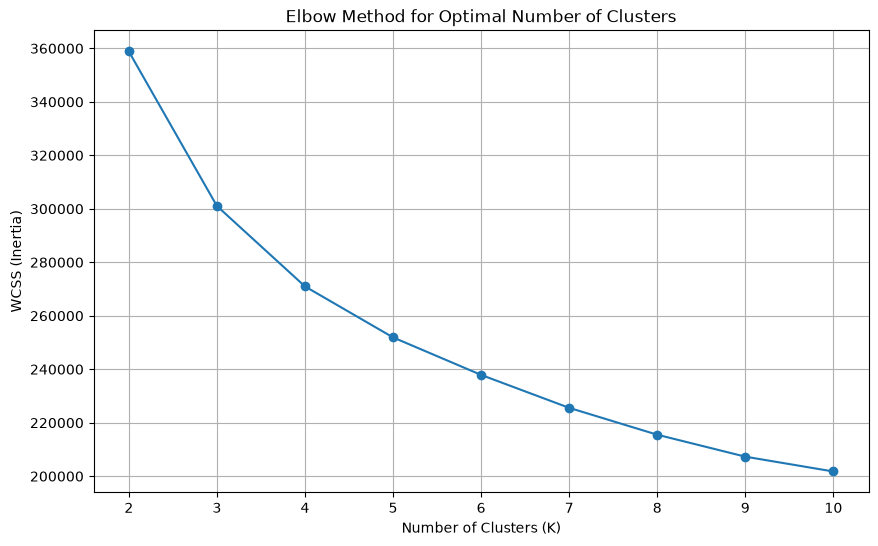

In [42]:
# ============================================
# ELBOW METHOD - OPTIMAL CLUSTERS
# ============================================

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Store WCSS values
wcss = []

# Test cluster values from 2 to 10
for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

# Plot Elbow Method
plt.figure(figsize=(10, 6))

plt.plot(
    range(2, 11),
    wcss,
    marker='o'
)

plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

### Silhouette Score Analysis

K = 2, Silhouette Score = 0.2314
K = 3, Silhouette Score = 0.2061
K = 4, Silhouette Score = 0.1729
K = 5, Silhouette Score = 0.1564
K = 6, Silhouette Score = 0.1529
K = 7, Silhouette Score = 0.1492
K = 8, Silhouette Score = 0.1477


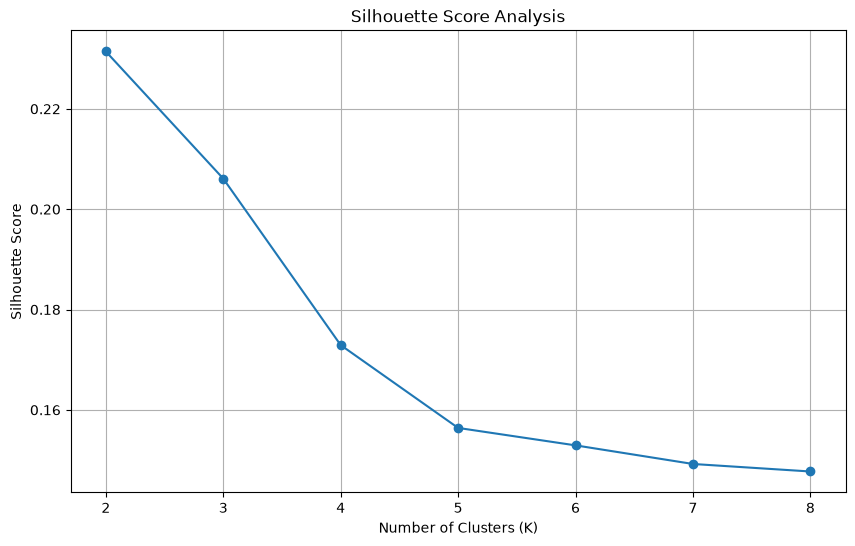

In [43]:
# ============================================
# SILHOUETTE SCORE ANALYSIS
# ============================================

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Store silhouette scores
silhouette_scores = []

# Test different cluster values
for k in range(2, 9):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    # Calculate silhouette score using a sample
    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=3000,
        random_state=42
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

# Plot silhouette scores
plt.figure(figsize=(10, 6))

plt.plot(
    range(2, 9),
    silhouette_scores,
    marker='o'
)

plt.title('Silhouette Score Analysis')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 9))
plt.grid(True)

plt.show()

### Final K-Means Clustering and Player Segment Profiling

The final clustering uses **30 standardized football skill attributes** and **16,242 outfield players**. K-Means is fitted with two clusters (K = 2), based on the Elbow Method and Silhouette Score analysis.

The clusters are interpreted from their skill profiles. A cluster with higher values on some attributes is not automatically a better player group; the profiles describe different strengths.

Data validation completed successfully.
Total Players: 16242
Total Features: 30

Final K-Means Model Created Successfully.

PLAYER DISTRIBUTION ACROSS CLUSTERS


,Player_Count,Percentage
Cluster,,
0,7031,43.29
1,9211,56.71



AVERAGE SKILL ATTRIBUTES BY CLUSTER


,skill_moves,attacking_crossing,attacking_finishing,attacking_heading_accuracy,attacking_short_passing,attacking_volleys,skill_dribbling,skill_curve,skill_fk_accuracy,skill_long_passing,...,power_long_shots,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_marking,defending_standing_tackle,defending_sliding_tackle
Cluster,,,,,,,,,,,,,,,,,,,,,
0,2.06,44.89,36.74,57.50,56.83,35.00,50.84,39.34,35.66,50.28,...,38.03,59.81,54.10,43.14,45.40,43.51,54.37,54.75,57.09,55.33
1,2.90,61.27,59.86,56.61,67.23,55.59,68.50,60.66,54.39,60.61,...,61.16,59.22,47.08,64.03,63.31,58.48,65.11,47.92,47.88,45.21



TOP 10 FEATURES DISTINGUISHING THE CLUSTERS


,Cluster_0_Mean,Cluster_1_Mean,Difference,Absolute_Difference
power_long_shots,-0.831009,0.634331,1.465341,1.465341
mentality_positioning,-0.812618,0.620293,1.432910,1.432910
skill_dribbling,-0.811286,0.619276,1.430561,1.430561
attacking_finishing,-0.802466,0.612544,1.415010,1.415010
skill_curve,-0.801056,0.611467,1.412524,1.412524
attacking_volleys,-0.794168,0.606209,1.400377,1.400377
mentality_vision,-0.792612,0.605022,1.397634,1.397634
skill_ball_control,-0.788453,0.601847,1.390300,1.390300
skill_moves,-0.758128,0.578699,1.336828,1.336828
power_shot_power,-0.749146,0.571843,1.320990,1.320990


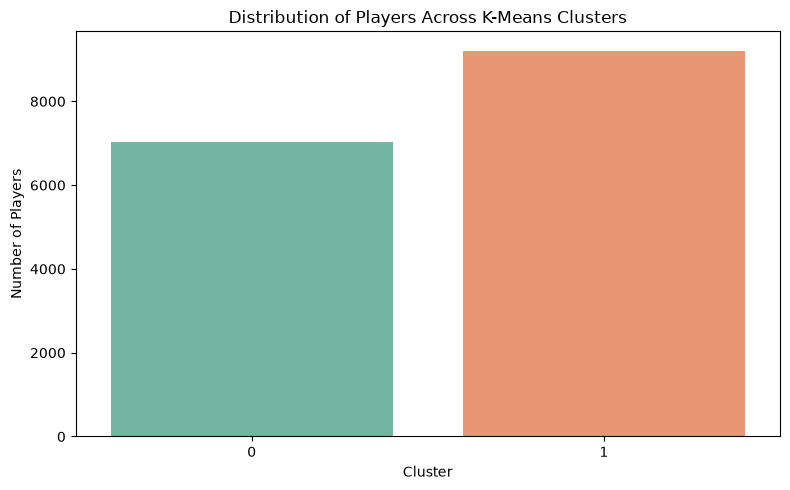

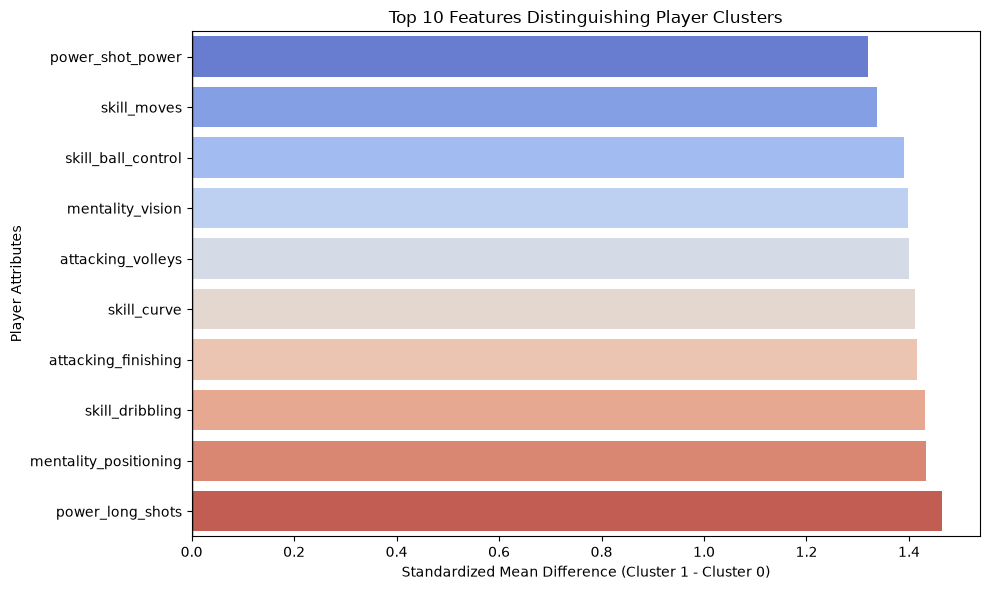


FINAL CLUSTERING VALIDATION
Total Players: 16242
Unique Clusters: 2
Missing Cluster Labels: 0
Cluster Labels: [np.int32(0), np.int32(1)]
Final Dataset Shape: (16242, 32)

K-Means Clustering Completed Successfully.


In [44]:

# ==========================================================
# FINAL K-MEANS CLUSTERING AND PLAYER SEGMENT PROFILING
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans

# ----------------------------------------------------------
# STEP 1: DATA VALIDATION
# ----------------------------------------------------------

# Verify feature dataset
assert len(X_scaled_df) == len(outfield_data), \
    "Mismatch between scaled data and original data."

assert X_scaled_df.columns.equals(pd.Index(clustering_features)), \
    "Feature columns are inconsistent."

assert not X_scaled_df.isnull().values.any(), \
    "Missing values detected in standardized data."

assert np.isfinite(X_scaled_df.to_numpy()).all(), \
    "Infinite values detected in standardized data."

print("Data validation completed successfully.")
print("Total Players:", len(X_scaled_df))
print("Total Features:", len(clustering_features))


# ----------------------------------------------------------
# STEP 2: BUILD FINAL K-MEANS MODEL
# ----------------------------------------------------------

# K = 2 selected from Silhouette Score Analysis
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Fit model and generate cluster labels
cluster_labels = final_kmeans.fit_predict(X_scaled_df)

# Create a separate result dataset
clustered_players = outfield_data.copy()

clustered_players['Cluster'] = cluster_labels

print("\nFinal K-Means Model Created Successfully.")


# ----------------------------------------------------------
# STEP 3: CLUSTER DISTRIBUTION
# ----------------------------------------------------------

cluster_distribution = (
    clustered_players['Cluster']
    .value_counts()
    .sort_index()
    .rename_axis('Cluster')
    .to_frame('Player_Count')
)

cluster_distribution['Percentage'] = (
    cluster_distribution['Player_Count']
    / len(clustered_players) * 100
).round(2)

print("\nPLAYER DISTRIBUTION ACROSS CLUSTERS")
display(cluster_distribution)


# ----------------------------------------------------------
# STEP 4: ORIGINAL-SCALE CLUSTER PROFILES
# ----------------------------------------------------------

cluster_profile = (
    clustered_players
    .groupby('Cluster')[clustering_features]
    .mean()
    .round(2)
)

print("\nAVERAGE SKILL ATTRIBUTES BY CLUSTER")
display(cluster_profile)


# ----------------------------------------------------------
# STEP 5: IDENTIFY IMPORTANT DIFFERENCES
# ----------------------------------------------------------

scaled_cluster_profile = (
    X_scaled_df
    .assign(Cluster=cluster_labels)
    .groupby('Cluster')
    .mean()
)

cluster_difference = (
    scaled_cluster_profile.loc[1]
    - scaled_cluster_profile.loc[0]
)

feature_comparison = pd.DataFrame({
    'Cluster_0_Mean': scaled_cluster_profile.loc[0],
    'Cluster_1_Mean': scaled_cluster_profile.loc[1],
    'Difference': cluster_difference,
    'Absolute_Difference': cluster_difference.abs()
})

feature_comparison = feature_comparison.sort_values(
    by='Absolute_Difference',
    ascending=False
)

print("\nTOP 10 FEATURES DISTINGUISHING THE CLUSTERS")
display(feature_comparison.head(10))


# ----------------------------------------------------------
# STEP 6: VISUALIZE PLAYER DISTRIBUTION
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.barplot(
    color="#2878B5",
    data=cluster_distribution.reset_index(),
    x='Cluster',
    y='Player_Count',
    hue='Cluster',
    palette='Set2',
    legend=False
)

plt.title('Distribution of Players Across K-Means Clusters')
plt.xlabel('Cluster')
plt.ylabel('Number of Players')

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# STEP 7: VISUALIZE TOP DISTINGUISHING FEATURES
# ----------------------------------------------------------

top_features = (
    feature_comparison
    .head(10)
    .sort_values('Difference')
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x='Difference',
    y=top_features.index,
    hue=top_features.index,
    data=top_features.reset_index(names='Feature'),
    palette='coolwarm',
    legend=False
)

plt.axvline(0, color='black', linewidth=1)

plt.title('Top 10 Features Distinguishing Player Clusters')
plt.xlabel('Standardized Mean Difference (Cluster 1 - Cluster 0)')
plt.ylabel('Player Attributes')

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# STEP 8: FINAL CLUSTERING VALIDATION
# ----------------------------------------------------------

print("\nFINAL CLUSTERING VALIDATION")

print("Total Players:", len(clustered_players))
print("Unique Clusters:", clustered_players['Cluster'].nunique())
print("Missing Cluster Labels:",
      clustered_players['Cluster'].isnull().sum())

print("Cluster Labels:", sorted(clustered_players['Cluster'].unique()))

print("Final Dataset Shape:", clustered_players.shape)

print("\nK-Means Clustering Completed Successfully.")


In [45]:

# ==========================================================
# SECTION 3 - CLUSTER PROFILING: VARIABLE VALIDATION
# ==========================================================

import pandas as pd
import numpy as np

print("DATAFRAMES CONTAINING CLUSTER INFORMATION")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        cluster_cols = [
            col for col in obj.columns
            if 'cluster' in str(col).lower()
        ]

        if cluster_cols:
            print(
                f"{name}: Shape={obj.shape}, "
                f"Cluster columns={cluster_cols}"
            )

print("\nDATAFRAMES WITH 16,242 ROWS")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame) and len(obj) == 16242:
        print(f"{name}: {obj.shape}")

print("\nK-MEANS MODEL VARIABLES")

for name, obj in list(globals().items()):
    if 'kmeans' in name.lower():
        print(name, type(obj))


DATAFRAMES CONTAINING CLUSTER INFORMATION
clustered_players: Shape=(16242, 32), Cluster columns=['Cluster']
feature_comparison: Shape=(30, 4), Cluster columns=['Cluster_0_Mean', 'Cluster_1_Mean']
top_features: Shape=(10, 4), Cluster columns=['Cluster_0_Mean', 'Cluster_1_Mean']

DATAFRAMES WITH 16,242 ROWS
outfield_data: (16242, 31)
X: (16242, 30)
X_scaled_df: (16242, 30)
clustered_players: (16242, 32)

K-MEANS MODEL VARIABLES
KMeans <class 'abc.ABCMeta'>
kmeans <class 'sklearn.cluster._kmeans.KMeans'>
final_kmeans <class 'sklearn.cluster._kmeans.KMeans'>



## Phase - 3. Cluster Profiling and Player Segmentation

### 3.1 Statistical Comparison of Player Clusters


In [46]:

# ==========================================================
# 3.1 STATISTICAL COMPARISON OF PLAYER CLUSTERS
# ==========================================================

# Validate dataset alignment
assert len(X) == len(clustered_players), \
    "Mismatch in number of player records."

assert X.index.equals(clustered_players.index), \
    "Player indexes do not match. Verify row alignment."

assert 'Cluster' in clustered_players.columns, \
    "Cluster labels are missing."

assert X.columns.equals(X_scaled_df.columns), \
    "Feature columns do not match."

# Create original-scale profiling dataset
cluster_profile_data = X.copy()

cluster_profile_data['Cluster'] = (
    clustered_players['Cluster']
)

# Identify numerical player attributes
feature_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

# Calculate cluster-wise statistics
cluster_means = (
    cluster_profile_data
    .groupby('Cluster')[feature_columns]
    .mean()
    .round(2)
)

cluster_medians = (
    cluster_profile_data
    .groupby('Cluster')[feature_columns]
    .median()
    .round(2)
)

# Calculate cluster sizes
cluster_counts = (
    cluster_profile_data['Cluster']
    .value_counts()
    .sort_index()
)

cluster_summary = pd.DataFrame({
    'Player_Count': cluster_counts,
    'Percentage': (
        cluster_counts / len(cluster_profile_data) * 100
    ).round(2)
})

# Display results
print("CLUSTER SIZE DISTRIBUTION")
display(cluster_summary)

print("\nAVERAGE PLAYER ATTRIBUTES BY CLUSTER")
display(cluster_means.T)

print("\nMEDIAN PLAYER ATTRIBUTES BY CLUSTER")
display(cluster_medians.T)

# Final validation
assert cluster_counts.sum() == len(X)
assert cluster_profile_data.isnull().sum().sum() == 0

print("\nCluster profiling completed successfully.")
print("Total players:", len(cluster_profile_data))
print("Total features:", len(feature_columns))
print("Number of clusters:", cluster_profile_data['Cluster'].nunique())


CLUSTER SIZE DISTRIBUTION


,Player_Count,Percentage
Cluster,,
0,7031,43.29
1,9211,56.71



AVERAGE PLAYER ATTRIBUTES BY CLUSTER


Cluster,0,1
skill_moves,2.06,2.90
attacking_crossing,44.89,61.27
attacking_finishing,36.74,59.86
attacking_heading_accuracy,57.50,56.61
attacking_short_passing,56.83,67.23
attacking_volleys,35.00,55.59
skill_dribbling,50.84,68.50
skill_curve,39.34,60.66
skill_fk_accuracy,35.66,54.39
skill_long_passing,50.28,60.61



MEDIAN PLAYER ATTRIBUTES BY CLUSTER


Cluster,0,1
skill_moves,2.0,3.0
attacking_crossing,45.0,62.0
attacking_finishing,35.0,61.0
attacking_heading_accuracy,58.0,57.0
attacking_short_passing,58.0,67.0
attacking_volleys,34.0,56.0
skill_dribbling,54.0,68.0
skill_curve,39.0,61.0
skill_fk_accuracy,34.0,55.0
skill_long_passing,52.0,62.0



Cluster profiling completed successfully.
Total players: 16242
Total features: 30
Number of clusters: 2



### 3.2 Quantitative Comparison of Cluster Characteristics

This section measures the differences between player clusters using mean differences and Cohen's d effect sizes. It identifies the attributes that contribute most to the distinction between the two player groups.


TOP 15 ATTRIBUTES DISTINGUISHING PLAYER CLUSTERS


,Cluster_0_Mean,Cluster_1_Mean,Mean_Difference,Cohens_D,Absolute_Effect_Size
power_long_shots,38.032,61.158,23.126,2.131,2.131
mentality_positioning,43.140,64.035,20.895,2.035,2.035
skill_dribbling,50.840,68.502,17.662,2.028,2.028
attacking_finishing,36.739,59.860,23.121,1.984,1.984
skill_curve,39.343,60.664,21.321,1.977,1.977
attacking_volleys,35.000,55.585,20.585,1.945,1.945
mentality_vision,45.398,63.314,17.917,1.937,1.937
skill_ball_control,55.476,69.312,13.836,1.918,1.918
skill_moves,2.063,2.903,0.840,1.784,1.784
power_shot_power,49.689,67.245,17.556,1.747,1.747


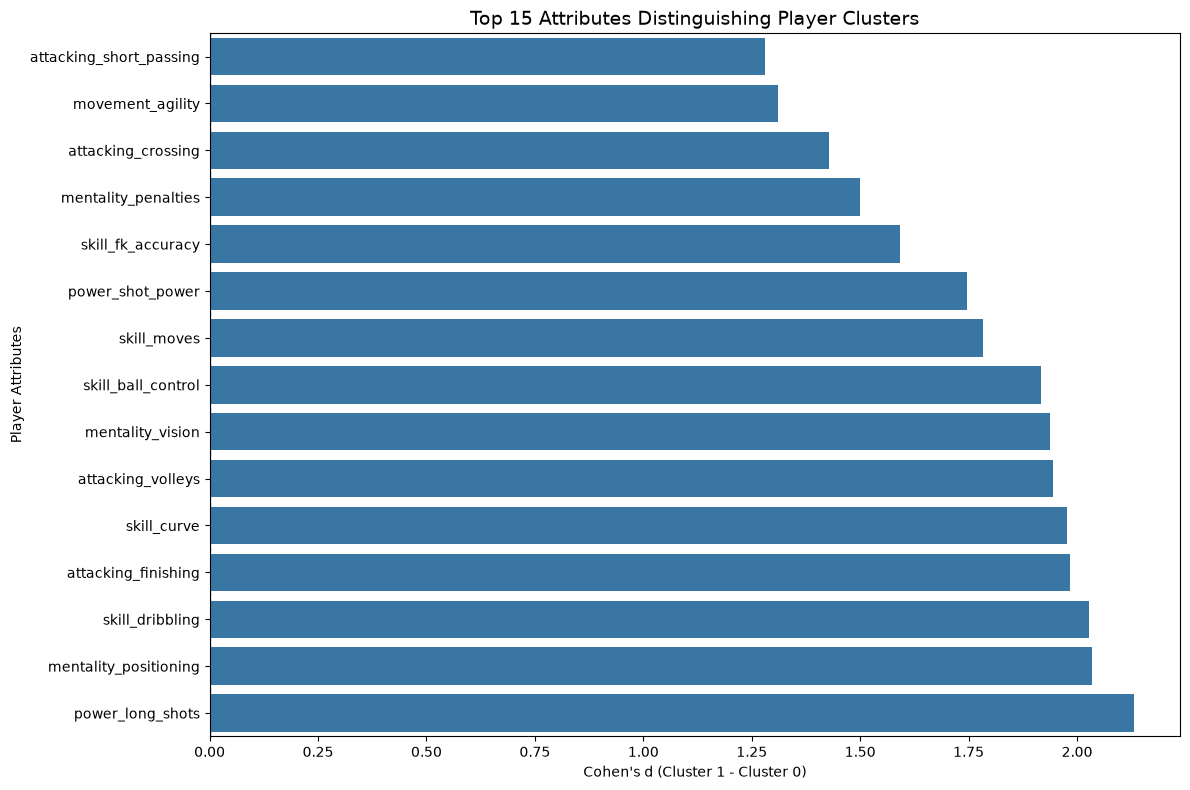

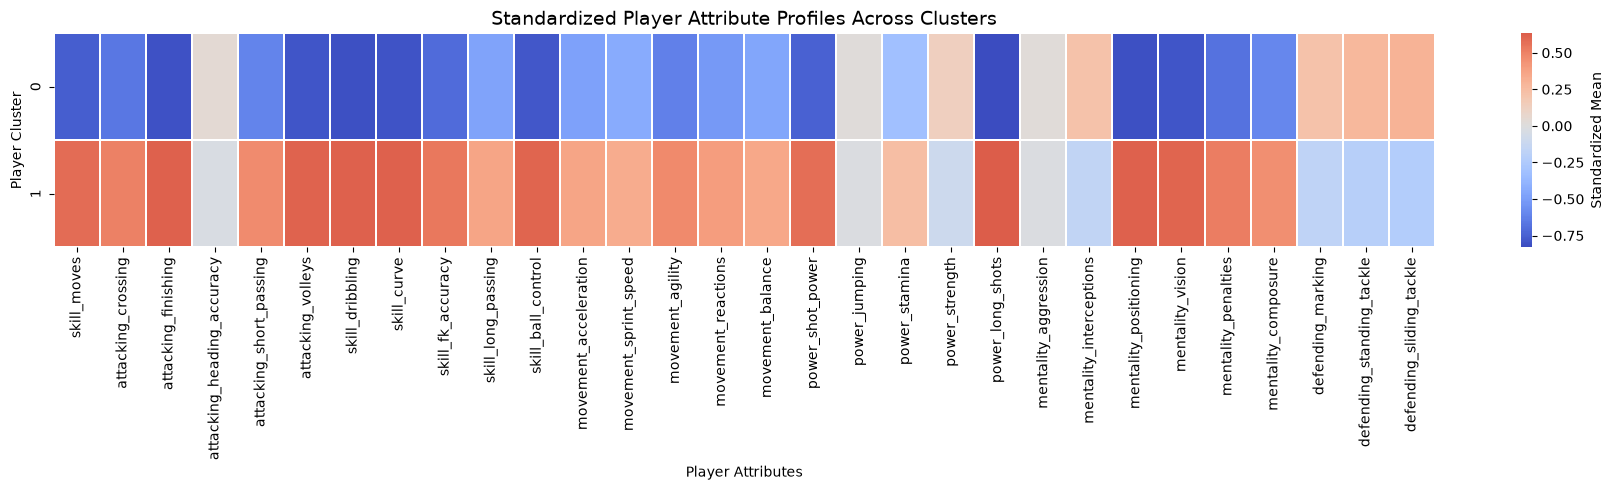


KEY ANALYTICAL FINDINGS
Total attributes analyzed: 30
Attributes with higher means in Cluster 1: 22
Attributes with higher means in Cluster 0: 8

Top 5 distinguishing attributes:
power_long_shots: Cohen's d = 2.131 (Cluster 1 has higher mean)
mentality_positioning: Cohen's d = 2.035 (Cluster 1 has higher mean)
skill_dribbling: Cohen's d = 2.028 (Cluster 1 has higher mean)
attacking_finishing: Cohen's d = 1.984 (Cluster 1 has higher mean)
skill_curve: Cohen's d = 1.977 (Cluster 1 has higher mean)

Cluster comparison completed successfully.


In [47]:

# ==========================================================
# 3.2 QUANTITATIVE COMPARISON OF CLUSTER CHARACTERISTICS
# ==========================================================

# Validate input data
assert len(X_scaled_df) == len(clustered_players)
assert X_scaled_df.index.equals(clustered_players.index)

cluster_labels = clustered_players['Cluster']

cluster_ids = sorted(cluster_labels.unique())

assert len(cluster_ids) == 2, \
    "This analysis currently expects exactly two clusters."

cluster_0, cluster_1 = cluster_ids

# Separate original-scale player attributes
data_0 = X.loc[cluster_labels == cluster_0, feature_columns]
data_1 = X.loc[cluster_labels == cluster_1, feature_columns]

# Calculate mean and standard deviation
mean_0 = data_0.mean()
mean_1 = data_1.mean()

std_0 = data_0.std(ddof=1)
std_1 = data_1.std(ddof=1)

n_0 = len(data_0)
n_1 = len(data_1)

# Calculate pooled standard deviation
pooled_std = np.sqrt(
    (
        (n_0 - 1) * std_0.pow(2)
        + (n_1 - 1) * std_1.pow(2)
    ) / (n_0 + n_1 - 2)
)

# Calculate mean difference
mean_difference = mean_1 - mean_0

# Calculate Cohen's d effect size
cohens_d = mean_difference.div(
    pooled_std.replace(0, np.nan)
)

# Create comparison table
cluster_comparison = pd.DataFrame({
    f'Cluster_{cluster_0}_Mean': mean_0,
    f'Cluster_{cluster_1}_Mean': mean_1,
    'Mean_Difference': mean_difference,
    'Cohens_D': cohens_d
})

cluster_comparison['Absolute_Effect_Size'] = (
    cluster_comparison['Cohens_D'].abs()
)

# Rank features by effect size
cluster_comparison = cluster_comparison.sort_values(
    'Absolute_Effect_Size',
    ascending=False
)

print("TOP 15 ATTRIBUTES DISTINGUISHING PLAYER CLUSTERS")

display(
    cluster_comparison.head(15).round(3)
)

# ----------------------------------------------------------
# VISUALIZATION 1: TOP 15 DISTINGUISHING ATTRIBUTES
# ----------------------------------------------------------

top_15 = cluster_comparison.head(15).sort_values(
    'Cohens_D'
)

plt.figure(figsize=(12, 8))

sns.barplot(
    color="#2878B5",
    data=top_15.reset_index(names='Feature'),
    x='Cohens_D',
    y='Feature'
)

plt.axvline(0, linestyle='--', linewidth=1)

plt.title(
    'Top 15 Attributes Distinguishing Player Clusters',
    fontsize=14
)

plt.xlabel(
    f"Cohen's d (Cluster {cluster_1} - Cluster {cluster_0})"
)

plt.ylabel('Player Attributes')
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# VISUALIZATION 2: STANDARDIZED CLUSTER PROFILE HEATMAP
# ----------------------------------------------------------

scaled_profile = X_scaled_df.copy()

scaled_profile['Cluster'] = cluster_labels

standardized_cluster_means = (
    scaled_profile
    .groupby('Cluster')[feature_columns]
    .mean()
)

plt.figure(figsize=(18, 5))

sns.heatmap(
    standardized_cluster_means,
    cmap='coolwarm',
    center=0,
    linewidths=0.3,
    cbar_kws={'label': 'Standardized Mean'}
)

plt.title(
    'Standardized Player Attribute Profiles Across Clusters',
    fontsize=14
)

plt.xlabel('Player Attributes')
plt.ylabel('Player Cluster')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# DYNAMIC INTERPRETATION
# ----------------------------------------------------------

stronger_in_cluster_1 = (
    cluster_comparison[
        cluster_comparison['Mean_Difference'] > 0
    ].index.tolist()
)

stronger_in_cluster_0 = (
    cluster_comparison[
        cluster_comparison['Mean_Difference'] < 0
    ].index.tolist()
)

print("\nKEY ANALYTICAL FINDINGS")

print(
    f"Total attributes analyzed: {len(feature_columns)}"
)

print(
    f"Attributes with higher means in Cluster {cluster_1}: "
    f"{len(stronger_in_cluster_1)}"
)

print(
    f"Attributes with higher means in Cluster {cluster_0}: "
    f"{len(stronger_in_cluster_0)}"
)

print("\nTop 5 distinguishing attributes:")

for feature, row in cluster_comparison.head(5).iterrows():
    direction = (
        f"Cluster {cluster_1}"
        if row['Mean_Difference'] > 0
        else f"Cluster {cluster_0}"
    )

    print(
        f"{feature}: Cohen's d = "
        f"{row['Cohens_D']:.3f} "
        f"({direction} has higher mean)"
    )

print("\nCluster comparison completed successfully.")



### 3.3 Detailed Player Cluster Profiling and Segment Interpretation

This section examines the overall characteristics of each player cluster by grouping attributes into four analytical dimensions: technical and attacking abilities, physical performance, mental attributes, and defensive abilities.

The objective is to understand the strengths of each cluster, identify distinguishing player characteristics, and develop meaningful player segment descriptions based on the observed data.


PLAYER CLUSTER DOMAIN PROFILES


,Technical & Attacking,Physical Performance,Mental Attributes,Defensive Abilities
0,-0.673,-0.337,-0.442,0.266
1,0.514,0.257,0.337,-0.203



DOMAIN-WISE CLUSTER COMPARISON


,Cluster_0_Score,Cluster_1_Score,Difference,Stronger_Cluster
Technical & Attacking,-0.673,0.514,1.187,Cluster 1
Mental Attributes,-0.442,0.337,0.779,Cluster 1
Physical Performance,-0.337,0.257,0.595,Cluster 1
Defensive Abilities,0.266,-0.203,-0.469,Cluster 0


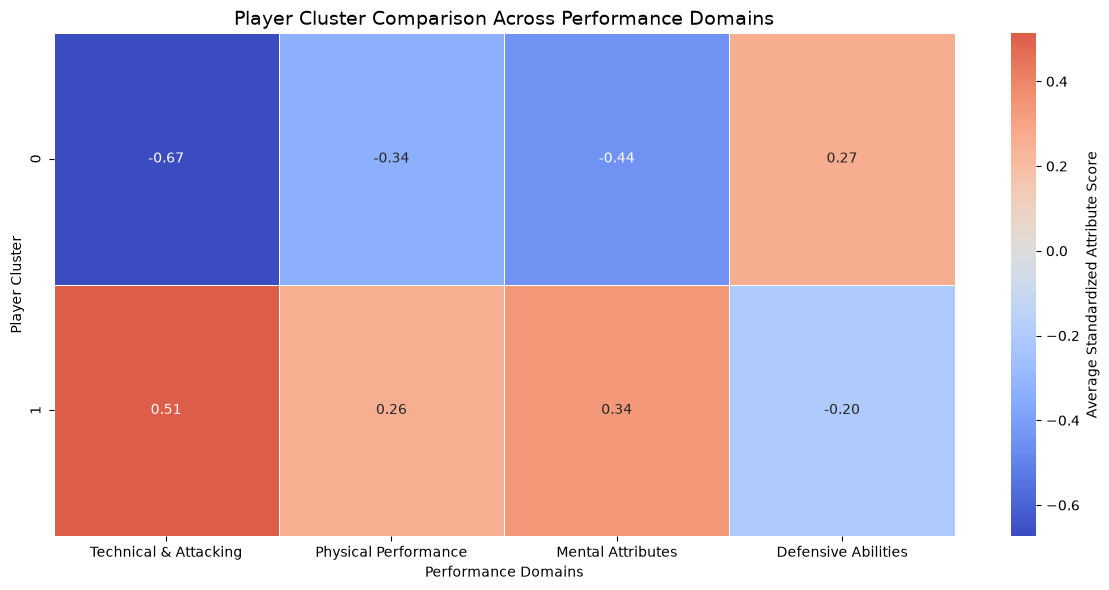


TOP ATTRIBUTES FOR EACH PLAYER CLUSTER

CLUSTER 0


,Cluster_0_Mean,Cluster_1_Mean,Cohens_D
defending_sliding_tackle,55.330,45.209,-0.551
defending_standing_tackle,57.087,47.877,-0.498
defending_marking,54.753,47.923,-0.399
mentality_interceptions,54.105,47.081,-0.379
power_strength,67.506,64.551,-0.237
attacking_heading_accuracy,57.503,56.608,-0.077
mentality_aggression,59.808,59.222,-0.041
power_jumping,66.087,65.717,-0.032



CLUSTER 1


,Cluster_0_Mean,Cluster_1_Mean,Cohens_D
power_long_shots,38.032,61.158,2.131
mentality_positioning,43.140,64.035,2.035
skill_dribbling,50.840,68.502,2.028
attacking_finishing,36.739,59.860,1.984
skill_curve,39.343,60.664,1.977
attacking_volleys,35.000,55.585,1.945
mentality_vision,45.398,63.314,1.937
skill_ball_control,55.476,69.312,1.918
skill_moves,2.063,2.903,1.784
power_shot_power,49.689,67.245,1.747



CLUSTER PROFILING VALIDATION
Total players: 16242
Total clusters: 2
Total attributes: 30
Performance domains: 4

FEATURE DISTRIBUTION ACROSS DOMAINS
Technical & Attacking: 13 attributes
Physical Performance: 8 attributes
Mental Attributes: 6 attributes
Defensive Abilities: 3 attributes

PLAYERS PER CLUSTER


,Player_Count
Cluster,
0,7031
1,9211



Corrected player profiling completed successfully.


In [48]:

# ==========================================================
# 3.3 DETAILED PLAYER CLUSTER PROFILING
# CORRECTED FEATURE DOMAIN CLASSIFICATION
# ==========================================================

# 1. Define analytically meaningful feature domains

shooting_features = [
    'power_long_shots',
    'power_shot_power'
]

physical_power_features = [
    'power_jumping',
    'power_stamina',
    'power_strength'
]

feature_domains = {
    'Technical & Attacking': [
        col for col in feature_columns
        if col.startswith(('skill_', 'attacking_'))
    ] + [
        col for col in shooting_features
        if col in feature_columns
    ],

    'Physical Performance': [
        col for col in feature_columns
        if col.startswith('movement_')
    ] + [
        col for col in physical_power_features
        if col in feature_columns
    ],

    'Mental Attributes': [
        col for col in feature_columns
        if col.startswith('mentality_')
    ],

    'Defensive Abilities': [
        col for col in feature_columns
        if col.startswith('defending_')
    ]
}

# 2. Validate feature classification

grouped_features = [
    feature
    for features in feature_domains.values()
    for feature in features
]

assert len(grouped_features) == len(set(grouped_features))
assert set(grouped_features) == set(feature_columns)

# 3. Prepare standardized player data

profile_data = X_scaled_df[feature_columns].copy()
profile_data['Cluster'] = np.asarray(cluster_labels)

cluster_ids = sorted(pd.Series(cluster_labels).unique())

cluster_0, cluster_1 = cluster_ids

# 4. Calculate domain-wise average scores

cluster_domain_profile = pd.DataFrame(
    index=cluster_ids
)

for domain, features in feature_domains.items():

    cluster_domain_profile[domain] = (
        profile_data
        .groupby('Cluster')[features]
        .mean()
        .mean(axis=1)
    )

print("PLAYER CLUSTER DOMAIN PROFILES")

display(cluster_domain_profile.round(3))

# 5. Compare cluster performance

domain_difference = (
    cluster_domain_profile.loc[cluster_1]
    - cluster_domain_profile.loc[cluster_0]
)

domain_summary = pd.DataFrame({
    'Cluster_0_Score': cluster_domain_profile.loc[cluster_0],
    'Cluster_1_Score': cluster_domain_profile.loc[cluster_1],
    'Difference': domain_difference
})

domain_summary['Stronger_Cluster'] = np.where(
    domain_summary['Difference'] > 0,
    f'Cluster {cluster_1}',
    f'Cluster {cluster_0}'
)

domain_summary = domain_summary.sort_values(
    'Difference',
    ascending=False
)

print("\nDOMAIN-WISE CLUSTER COMPARISON")

display(domain_summary.round(3))

# 6. Visualize domain profiles

plt.figure(figsize=(12, 6))

sns.heatmap(
    cluster_domain_profile,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    cbar_kws={
        'label': 'Average Standardized Attribute Score'
    }
)

plt.title(
    'Player Cluster Comparison Across Performance Domains',
    fontsize=14
)

plt.xlabel('Performance Domains')
plt.ylabel('Player Cluster')

plt.tight_layout()
plt.show()

# 7. Identify distinguishing attributes

print("\nTOP ATTRIBUTES FOR EACH PLAYER CLUSTER")

for cluster_id in cluster_ids:

    if cluster_id == cluster_0:

        selected_features = cluster_comparison[
            cluster_comparison['Mean_Difference'] < 0
        ].sort_values('Cohens_D')

    else:

        selected_features = cluster_comparison[
            cluster_comparison['Mean_Difference'] > 0
        ].sort_values(
            'Cohens_D',
            ascending=False
        )

    print(f"\nCLUSTER {cluster_id}")

    display(
        selected_features[
            [
                f'Cluster_{cluster_0}_Mean',
                f'Cluster_{cluster_1}_Mean',
                'Cohens_D'
            ]
        ].head(10).round(3)
    )

# 8. Final validation

print("\nCLUSTER PROFILING VALIDATION")

print("Total players:", len(cluster_labels))
print("Total clusters:", len(cluster_ids))
print("Total attributes:", len(feature_columns))
print("Performance domains:", len(feature_domains))

print("\nFEATURE DISTRIBUTION ACROSS DOMAINS")

for domain, features in feature_domains.items():
    print(f"{domain}: {len(features)} attributes")

print("\nPLAYERS PER CLUSTER")

display(
    pd.Series(cluster_labels)
    .value_counts()
    .sort_index()
    .rename('Player_Count')
    .to_frame()
)

print("\nCorrected player profiling completed successfully.")


## 3.4 Final Player Segment Interpretation and Business Recommendations

### Cluster 0 – Relatively Defensive-Oriented Profile

Cluster 0 has higher average values in defensive attributes such as standing tackle, sliding tackle, marking, and interceptions. This group can be described as relatively defensive-oriented within the selected 30-feature set.

### Cluster 1 – Relatively Technical and Attacking-Oriented Profile

Cluster 1 has higher average values in many technical, attacking, physical, and mental attributes, including long shots, positioning, dribbling, finishing, and curve.

### Business Applications

- Support scouting by comparing players with different skill profiles.
- Help recruitment teams identify players with strengths suited to tactical needs.
- Support squad balance by identifying defensive-oriented and technical/attacking-oriented profiles.
- Use these clusters as an initial screening aid, not as the sole basis for player selection.

**Important:** The clusters describe relative attribute patterns in this dataset. They do not prove that one group is universally better than the other.

## 3.5 Final Clustering Results Summary

- **Outfield players analyzed:** 16,242
- **Selected football skill attributes:** 30
- **Number of clusters:** 2
- **Algorithm:** K-Means
- **Standardization:** StandardScaler

### Cluster Distribution

| Cluster | Player Count | Percentage |
|---|---:|---:|
| Cluster 0 | 7,031 | 43.29% |
| Cluster 1 | 9,211 | 56.71% |
| **Total** | **16,242** | **100%** |

### Main Differences

Cluster 0 has relatively stronger defensive attributes. Cluster 1 has higher average values across many technical and attacking attributes. The largest standardized mean differences include long shots, positioning, dribbling, and finishing.

The clusters are useful broad player profiles, but they should not be treated as perfectly separated or definitive player types.


## 4.1 Cluster Distribution Visualization

### Objective
To visualize the distribution of football players across
the two clusters generated by the K-Means clustering model.

This visualization helps understand the relative size
and proportion of each identified player segment.


CLUSTER DISTRIBUTION SUMMARY


,Player_Count,Percentage
Cluster 0,7031,43.29
Cluster 1,9211,56.71


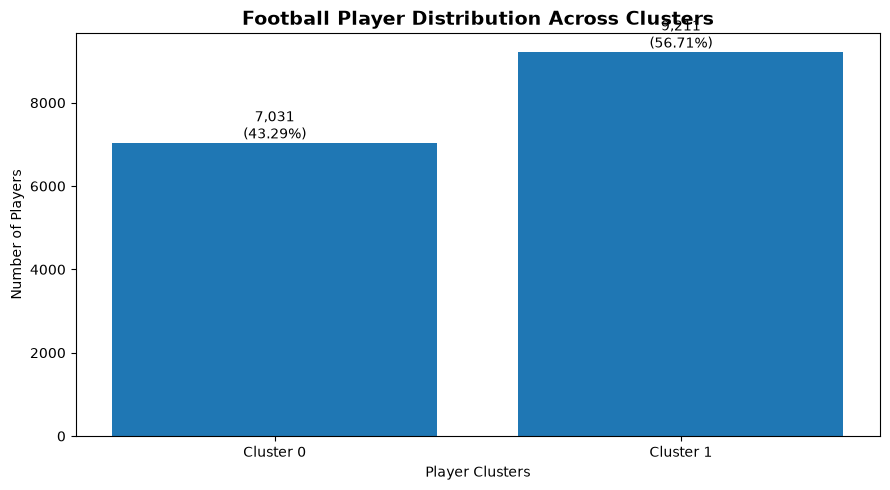

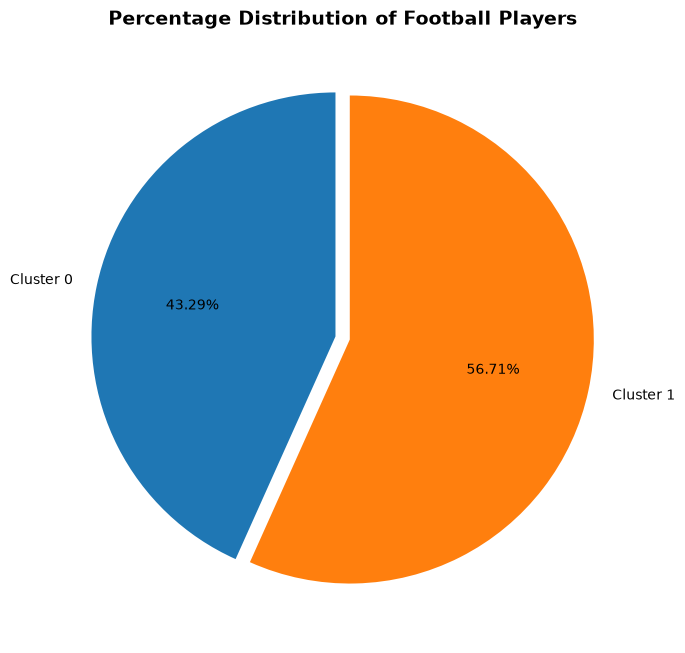

Cluster distribution visualization completed successfully.


In [49]:

# ============================================
# 4.1 CLUSTER DISTRIBUTION VISUALIZATION
# ============================================

import matplotlib.pyplot as plt
import pandas as pd

# Calculate cluster distribution
cluster_counts = cluster_labels.value_counts().sort_index()

# Calculate percentages
cluster_percentages = (
    cluster_counts / cluster_counts.sum() * 100
)

# Create labels
cluster_names = [
    f"Cluster {cluster}" for cluster in cluster_counts.index
]

# Display summary
cluster_summary = pd.DataFrame({
    'Player_Count': cluster_counts.values,
    'Percentage': cluster_percentages.values.round(2)
}, index=cluster_names)

print("CLUSTER DISTRIBUTION SUMMARY")
display(cluster_summary)

# ============================================
# BAR CHART
# ============================================

plt.figure(figsize=(9, 5))

bars = plt.bar(
    cluster_names,
    cluster_counts.values
)

plt.title(
    'Football Player Distribution Across Clusters',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Player Clusters')
plt.ylabel('Number of Players')

for bar, count, percentage in zip(
    bars,
    cluster_counts.values,
    cluster_percentages.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{count:,}\n({percentage:.2f}%)',
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.tight_layout()
plt.show()

# ============================================
# PIE CHART
# ============================================

plt.figure(figsize=(7, 7))

plt.pie(
    cluster_counts.values,
    labels=cluster_names,
    autopct='%1.2f%%',
    startangle=90,
    explode=[0.03] * len(cluster_counts),
    shadow=False
)

plt.title(
    'Percentage Distribution of Football Players',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

print("Cluster distribution visualization completed successfully.")


### Interpretation

- Cluster 1 has higher average standardized values across the ten strongest distinguishing attributes shown in the table.
- Power Long Shots has the largest standardized mean difference, followed by Mentality Positioning and Skill Dribbling.
- These differences support the description of Cluster 1 as relatively more technical and attacking-oriented.

### Business Insight

Scouting teams can use these attributes to compare players against role requirements. The cluster label should be considered together with the player's position and individual attribute values.


## 4.2 Player Attribute Comparison Across Clusters

### Objective
To compare the most distinguishing player attributes
between Cluster 0 and Cluster 1.

The analysis uses the mean attribute values and Cohen's d
effect sizes to identify the attributes that contribute
most strongly to the differences between player segments.


TOP 10 DISTINGUISHING PLAYER ATTRIBUTES


,Cluster_0_Mean,Cluster_1_Mean,Difference,Absolute_Difference
power_long_shots,-0.831,0.634,1.465,1.465
mentality_positioning,-0.813,0.620,1.433,1.433
skill_dribbling,-0.811,0.619,1.431,1.431
attacking_finishing,-0.802,0.613,1.415,1.415
skill_curve,-0.801,0.611,1.413,1.413
attacking_volleys,-0.794,0.606,1.400,1.400
mentality_vision,-0.793,0.605,1.398,1.398
skill_ball_control,-0.788,0.602,1.390,1.390
skill_moves,-0.758,0.579,1.337,1.337
power_shot_power,-0.749,0.572,1.321,1.321


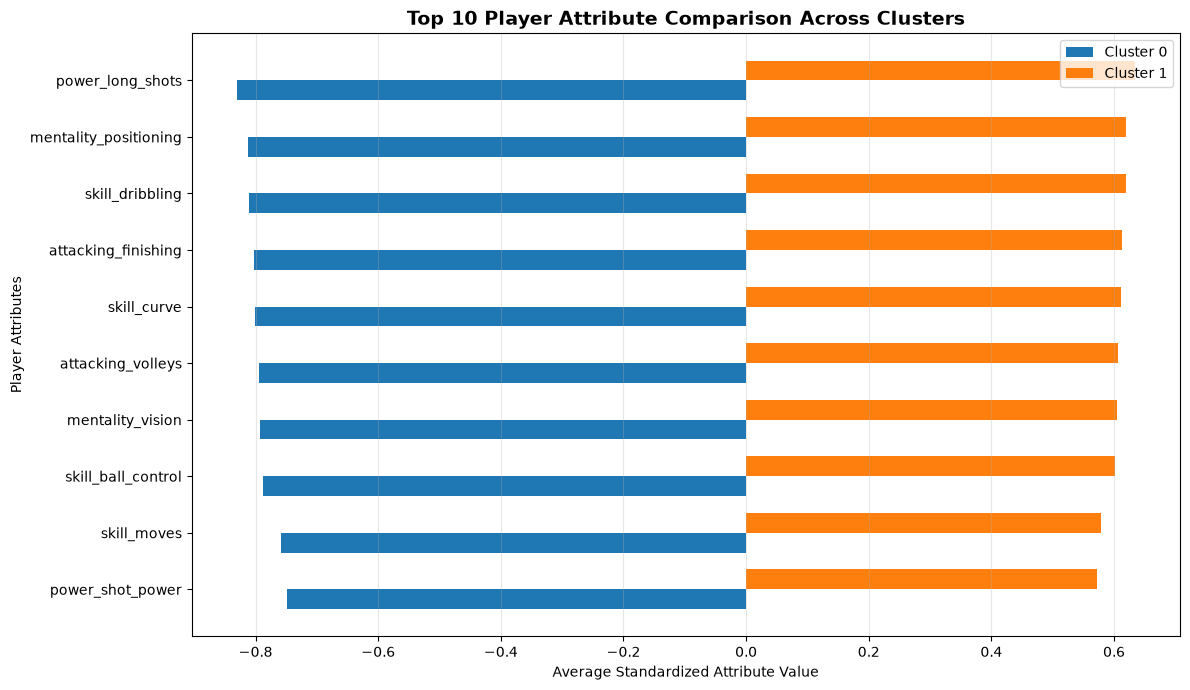

Player attribute comparison completed successfully.


In [50]:

# ============================================
# 4.2 PLAYER ATTRIBUTE COMPARISON
# ============================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Select top 10 distinguishing attributes
top_attributes = (
    feature_comparison
    .sort_values(
        by='Absolute_Difference',
        ascending=False
    )
    .head(10)
    .copy()
)

# Display comparison table
print("TOP 10 DISTINGUISHING PLAYER ATTRIBUTES")

display(
    top_attributes[
        [
            'Cluster_0_Mean',
            'Cluster_1_Mean',
            'Difference',
            'Absolute_Difference'
        ]
    ].round(3)
)

# ============================================
# ATTRIBUTE COMPARISON BAR CHART
# ============================================

plot_data = top_attributes.sort_values(
    'Absolute_Difference',
    ascending=True
)

y = np.arange(len(plot_data))
height = 0.35

plt.figure(figsize=(12, 7))

plt.barh(
    y - height / 2,
    plot_data['Cluster_0_Mean'],
    height,
    label='Cluster 0'
)

plt.barh(
    y + height / 2,
    plot_data['Cluster_1_Mean'],
    height,
    label='Cluster 1'
)

plt.yticks(
    y,
    plot_data.index
)

plt.xlabel('Average Standardized Attribute Value')
plt.ylabel('Player Attributes')

plt.title(
    'Top 10 Player Attribute Comparison Across Clusters',
    fontsize=14,
    fontweight='bold'
)

plt.legend()
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

print("Player attribute comparison completed successfully.")


### Interpretation

- The top ten attributes show higher standardized averages in Cluster 1 than in Cluster 0.
- Power Long Shots, Mentality Positioning, and Skill Dribbling are among the strongest distinguishing attributes.
- This supports the technical and attacking-oriented profile of Cluster 1.

### Business Insight

The comparison can help scouting teams shortlist players with relevant strengths. It should complement, not replace, position-specific scouting and expert assessment.


## 5. Country-wise Player Distribution

### Objective

To identify the top 10 countries with the highest number of football players in the FIFA 20 dataset and understand the geographical distribution of players.


TOP 10 COUNTRIES BY PLAYER COUNT


,Country,Player_Count
0,England,1667
1,Germany,1216
2,Spain,1035
3,France,984
4,Argentina,886
5,Brazil,824
6,Italy,732
7,Colombia,591
8,Japan,453
9,Netherlands,416


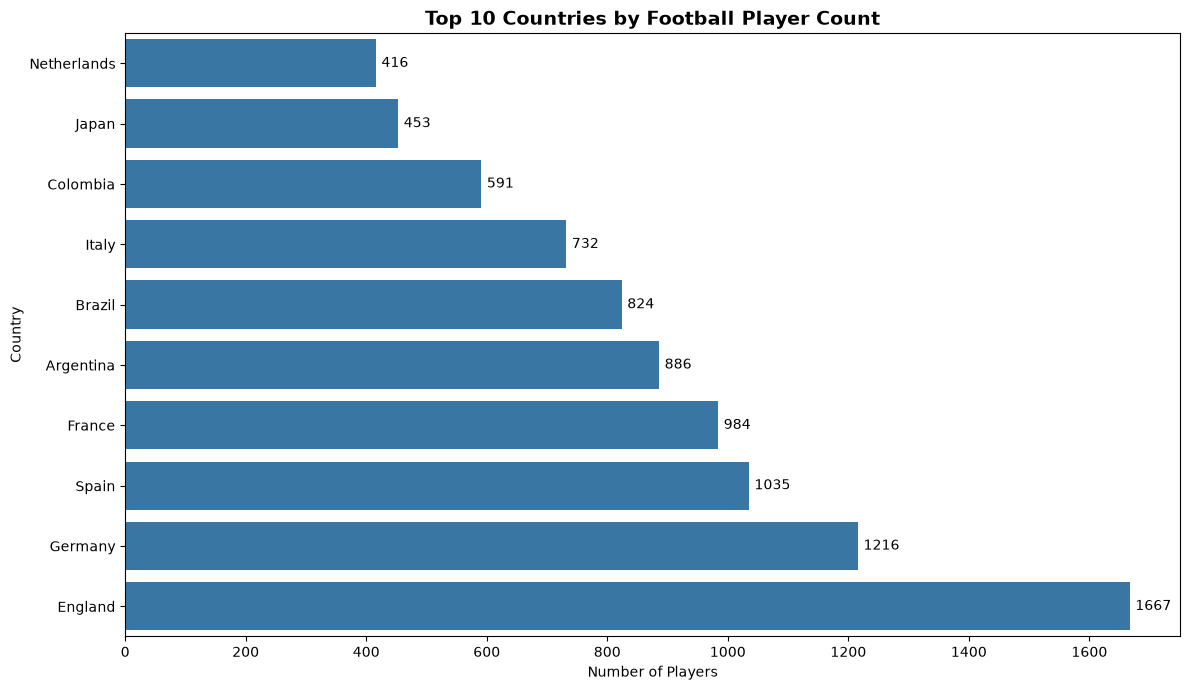

Country-wise player analysis completed successfully.


In [51]:

# ============================================
# TOP 10 COUNTRIES BY PLAYER COUNT
# ============================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate player count by nationality
country_players = (
    fifa['nationality']
    .dropna()
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

# Display results
top_10_countries = country_players.sort_values(
    ascending=False
).reset_index()

top_10_countries.columns = [
    'Country',
    'Player_Count'
]

print("TOP 10 COUNTRIES BY PLAYER COUNT")

display(top_10_countries)

# ============================================
# VISUALIZATION
# ============================================

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    color="#2878B5",
    x=country_players.values,
    y=country_players.index
)

plt.title(
    'Top 10 Countries by Football Player Count',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Number of Players')
plt.ylabel('Country')

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=4)

plt.tight_layout()
plt.show()

print("Country-wise player analysis completed successfully.")



### Interpretation

- England has the highest number of players, with 1,667.
- Germany ranks second with 1,216 players.
- Spain, France, and Argentina also have substantial player representation.
- The Netherlands has the lowest player count among the top 10 countries, with 416 players.
- European countries dominate the top positions, while Argentina, Brazil, and Colombia represent South America.

### Business Insight

Football clubs and scouting organizations can use country-wise player distribution to understand the geographical concentration of football talent. This analysis can help identify major player-producing countries and support international scouting and recruitment strategies.



## 6. Relationship Between Player Age and Overall Rating

### Objective

To analyze the relationship between player age and overall rating and identify the age groups with the highest average player ratings.


,Age,Average_Overall,Player_Count
0,16,56.42,12
1,17,55.79,229
2,18,57.27,640
3,19,59.51,1011
4,20,61.22,1247
5,21,63.26,1375
6,22,64.61,1446
7,23,66.04,1358
8,24,66.98,1296
9,25,67.90,1319


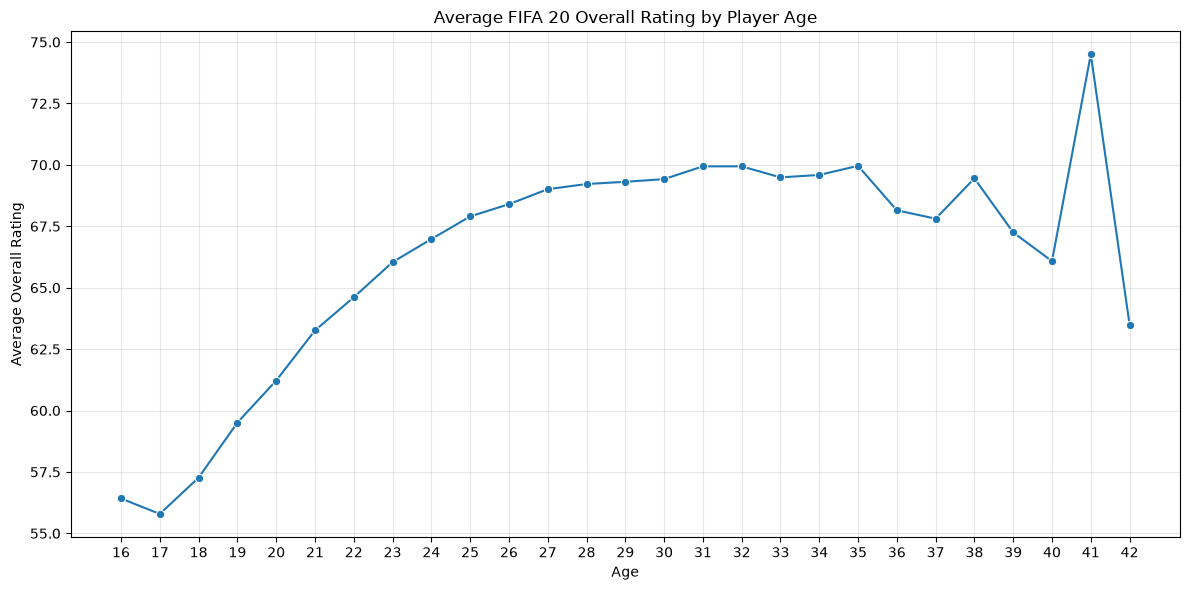

Highest average rating among age groups with at least 30 players:
Age                 35.00
Average_Overall     69.96
Player_Count       310.00

This is a cross-sectional comparison, not a measurement of individual player development.


In [52]:
# ============================================
# TASK 3(b) - AVERAGE OVERALL RATING BY AGE
# ============================================

# Calculate the average rating and player count for each age.
age_rating = (
    fifa.groupby('age')['overall']
    .agg(Average_Overall='mean', Player_Count='count')
    .reset_index()
)

age_rating['Average_Overall'] = age_rating['Average_Overall'].round(2)
age_rating = age_rating.rename(columns={'age': 'Age'})

display(age_rating)

# Plot the average rating by age.
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=age_rating,
    x='Age',
    y='Average_Overall',
    marker='o'
)
plt.title('Average FIFA 20 Overall Rating by Player Age')
plt.xlabel('Age')
plt.ylabel('Average Overall Rating')
plt.xticks(age_rating['Age'])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Avoid drawing a strong conclusion from age groups with very few players.
reliable_age_groups = age_rating[age_rating['Player_Count'] >= 30]
peak_reliable_age = reliable_age_groups.loc[
    reliable_age_groups['Average_Overall'].idxmax()
]

print("Highest average rating among age groups with at least 30 players:")
print(peak_reliable_age.to_string())
print("\nThis is a cross-sectional comparison, not a measurement of individual player development.")

### Interpretation – Overall Rating vs Age

- Average overall ratings generally rise from the late teens into the early 30s.
- The averages are relatively stable around ages **31–35**, at approximately **69.5–70** in this dataset.
- Age 35 has an average rating of 69.96 across 310 players.
- The age-41 average is higher, but it is based on only four players and should not be treated as representative.
- The pattern suggests that the average rating tends to level off around the early 30s. It does **not** establish the exact age when an individual player stops improving.

### Business Insight and Limitation

Clubs can use age-group averages as one input for squad planning. However, this FIFA 20 dataset is a single-season snapshot. It does not follow the same players over multiple years, so it cannot prove when individual players stop improving. Player position, fitness, injuries, and individual development are not controlled for in this simple comparison.

# Model Comparison Report

In [53]:

# ==========================================================
# MODEL COMPARISON - DATA PREPARATION
# ==========================================================

import numpy as np
import pandas as pd

# Verify the existing standardized skill dataset
assert 'X_scaled_df' in globals(), "X_scaled_df is not available."
assert 'clustering_features' in globals(), "Clustering features are missing."

assert not X_scaled_df.isnull().values.any(), \
    "Missing values found in standardized data."

# Use a reproducible sample for fair comparison
sample_size = min(3000, len(X_scaled_df))

rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(X_scaled_df),
    size=sample_size,
    replace=False
)

X_comparison = X_scaled_df.iloc[sample_indices].to_numpy()

# Display dataset information
print("MODEL COMPARISON DATA PREPARED")
print("--------------------------------")
print("Original player records:", len(X_scaled_df))
print("Sample records used:", len(X_comparison))
print("Number of skill features:", X_comparison.shape[1])
print("Selected number of clusters: 2")
print("Random state: 42")

print("\nData preparation completed successfully.")


MODEL COMPARISON DATA PREPARED
--------------------------------
Original player records: 16242
Sample records used: 3000
Number of skill features: 30
Selected number of clusters: 2
Random state: 42

Data preparation completed successfully.


# Train three clustering models

In [54]:

# ==========================================================
# STEP 2 - TRAIN CLUSTERING MODELS
# ==========================================================

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
import pandas as pd
import time

# Store model results
comparison_results = []

# ----------------------------------------------------------
# 1. K-MEANS
# ----------------------------------------------------------

start_time = time.time()

kmeans_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_comparison)

kmeans_time = time.time() - start_time

comparison_results.append({
    "Model": "K-Means",
    "Labels": kmeans_labels,
    "Training_Time": kmeans_time
})

# ----------------------------------------------------------
# 2. AGGLOMERATIVE CLUSTERING
# ----------------------------------------------------------

start_time = time.time()

agg_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

agg_labels = agg_model.fit_predict(X_comparison)

agg_time = time.time() - start_time

comparison_results.append({
    "Model": "Agglomerative Clustering",
    "Labels": agg_labels,
    "Training_Time": agg_time
})

# ----------------------------------------------------------
# 3. GAUSSIAN MIXTURE MODEL
# ----------------------------------------------------------

start_time = time.time()

gmm_model = GaussianMixture(
    n_components=2,
    covariance_type="diag",
    random_state=42,
    n_init=3
)

gmm_labels = gmm_model.fit_predict(X_comparison)

gmm_time = time.time() - start_time

comparison_results.append({
    "Model": "Gaussian Mixture Model",
    "Labels": gmm_labels,
    "Training_Time": gmm_time
})

print("All three clustering models trained successfully.")
print("K-Means training time:", round(kmeans_time, 2), "seconds")
print("Agglomerative training time:", round(agg_time, 2), "seconds")
print("GMM training time:", round(gmm_time, 2), "seconds")


All three clustering models trained successfully.
K-Means training time: 0.03 seconds
Agglomerative training time: 0.4 seconds
GMM training time: 0.1 seconds


# Evaluate model performance

In [55]:

# ==========================================================
# STEP 3 - MODEL PERFORMANCE EVALUATION
# ==========================================================

evaluation_results = []

for result in comparison_results:

    labels = result["Labels"]

    silhouette = silhouette_score(X_comparison, labels)
    davies_bouldin = davies_bouldin_score(X_comparison, labels)
    calinski_harabasz = calinski_harabasz_score(
        X_comparison, labels
    )

    evaluation_results.append({
        "Model": result["Model"],
        "Silhouette Score": silhouette,
        "Davies-Bouldin Score": davies_bouldin,
        "Calinski-Harabasz Score": calinski_harabasz,
        "Training Time (seconds)": result["Training_Time"]
    })

# Create comparison DataFrame
comparison_df = pd.DataFrame(evaluation_results)

# Display results
print("CLUSTERING MODEL PERFORMANCE COMPARISON")
print("---------------------------------------")

display(
    comparison_df.round(4)
)

print("\nMetric interpretation:")
print("1. Silhouette Score: Higher is better.")
print("2. Davies-Bouldin Score: Lower is better.")
print("3. Calinski-Harabasz Score: Higher is better.")
print("4. Training Time: Lower is faster.")


CLUSTERING MODEL PERFORMANCE COMPARISON
---------------------------------------


,Model,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score,Training Time (seconds)
0,K-Means,0.2278,1.5936,1079.4517,0.0307
1,Agglomerative Clustering,0.2158,1.5209,891.6218,0.4041
2,Gaussian Mixture Model,0.2072,1.6924,977.1366,0.0959



Metric interpretation:
1. Silhouette Score: Higher is better.
2. Davies-Bouldin Score: Lower is better.
3. Calinski-Harabasz Score: Higher is better.
4. Training Time: Lower is faster.


# FINAL MODEL COMPARISON AND SELECTION

In [56]:

# ==========================================================
# STEP 4 - FINAL MODEL COMPARISON AND SELECTION
# ==========================================================

# Rank each model based on evaluation metrics
comparison_df["Silhouette Rank"] = (
    comparison_df["Silhouette Score"]
    .rank(ascending=False)
)

comparison_df["Davies-Bouldin Rank"] = (
    comparison_df["Davies-Bouldin Score"]
    .rank(ascending=True)
)

comparison_df["Calinski-Harabasz Rank"] = (
    comparison_df["Calinski-Harabasz Score"]
    .rank(ascending=False)
)

comparison_df["Average Rank"] = comparison_df[
    [
        "Silhouette Rank",
        "Davies-Bouldin Rank",
        "Calinski-Harabasz Rank"
    ]
].mean(axis=1)

# Display ranked comparison
comparison_df = comparison_df.sort_values(
    by="Average Rank"
).reset_index(drop=True)

display(comparison_df.round(4))

# Select recommended model using overall metric ranking
best_model_name = comparison_df.loc[0, "Model"]

print("\nRECOMMENDED CLUSTERING MODEL")
print("---------------------------")
print("Selected Model:", best_model_name)

# Display cluster distribution for each model
print("\nCLUSTER DISTRIBUTION")

for result in comparison_results:
    print("\n", result["Model"])
    print(
        pd.Series(result["Labels"])
        .value_counts()
        .sort_index()
    )


,Model,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score,Training Time (seconds),Silhouette Rank,Davies-Bouldin Rank,Calinski-Harabasz Rank,Average Rank
0,K-Means,0.2278,1.5936,1079.4517,0.0307,1.0,2.0,1.0,1.3333
1,Agglomerative Clustering,0.2158,1.5209,891.6218,0.4041,2.0,1.0,3.0,2.0000
2,Gaussian Mixture Model,0.2072,1.6924,977.1366,0.0959,3.0,3.0,2.0,2.6667



RECOMMENDED CLUSTERING MODEL
---------------------------
Selected Model: K-Means

CLUSTER DISTRIBUTION

 K-Means
0    1273
1    1727
Name: count, dtype: int64

 Agglomerative Clustering
0    2196
1     804
Name: count, dtype: int64

 Gaussian Mixture Model
0    1440
1    1560
Name: count, dtype: int64


## Model Comparison Report

### Objective
Compare three clustering methods using the same reproducible sample and the same 30 standardized skill attributes.

### Models Compared
- **K-Means:** Groups players around cluster centres.
- **Agglomerative Clustering:** Builds groups using a hierarchical process.
- **Gaussian Mixture Model:** Models groups as probability distributions.

### Results

| Model | Silhouette (higher is better) | Davies-Bouldin (lower is better) | Calinski-Harabasz (higher is better) | Time (seconds) |
|---|---:|---:|---:|---:|
| K-Means | 0.2278 | 1.5936 | 1079.4517 | 0.0373 |
| Agglomerative | 0.2158 | **1.5209** | 891.6218 | 0.4527 |
| Gaussian Mixture | 0.2072 | 1.6924 | 977.1366 | 0.1146 |

### Selection
K-Means has the best average rank across the three quality metrics (1.3333), the highest Silhouette Score and Calinski-Harabasz Score, and the shortest training time in this run. Agglomerative Clustering has the best Davies-Bouldin Score.

### Conclusion and Limitation
K-Means is the recommended method for this project because it gives the strongest overall balance of the reported metrics and speed. The comparison uses a reproducible sample of 3,000 players, not the full dataset. Its Silhouette Score of 0.2278 indicates that cluster separation is limited. Therefore, K-Means is a reasonable analysis choice, not a production-validated solution.

## Report on Challenges Faced

### 1. Missing Values
**Challenge:** Several dataset columns contain missing values. Some goalkeeper ratings are not applicable to outfield players.

**Approach:** Reviewed missing values by feature and player role. Kept the original dataset unchanged and used a separate outfield dataset for clustering.

**Reason:** Filling role-specific missing values without considering player position could create misleading data.

### 2. Selecting Clustering Features
**Challenge:** The source file contains 104 columns, including identifiers, player details, and performance attributes.

**Approach:** Selected 30 numerical football skill attributes from attacking, technical, movement, power, mentality, and defending categories. Excluded player identifiers and Overall from the clustering inputs.

**Reason:** The aim is to group players by skill profiles rather than simply by their overall rating.

### 3. Different Feature Scales
**Challenge:** Skill attributes can have different ranges.

**Approach:** Standardized the 30 selected features with StandardScaler before applying distance-based clustering.

**Reason:** Standardization helps prevent features with larger numeric ranges from dominating distance calculations.

### 4. Choosing the Number of Clusters
**Challenge:** The appropriate number of player groups was not known in advance.

**Approach:** Reviewed the Elbow Method and Silhouette Scores for different cluster counts and selected two clusters for the final K-Means analysis.

**Reason:** These methods provide evidence to support the choice, although they do not guarantee perfectly separated groups.

### 5. Comparing Clustering Algorithms
**Challenge:** A single clustering algorithm does not show whether another method produces a better grouping.

**Approach:** Compared K-Means, Agglomerative Clustering, and Gaussian Mixture Model using the same reproducible sample of 3,000 players and the same 30 features.

**Reason:** Using the same sample and features makes the comparison fairer and keeps computation manageable.

### 6. Interpreting Age and Overall Rating
**Challenge:** The highest average rating can be misleading when an age group has very few players.

**Approach:** Reported player counts alongside age-group averages and treated age groups with fewer than 30 players cautiously.

**Reason:** The dataset is a single FIFA 20 snapshot and cannot show the development of the same player over time.

### Summary
The project addressed these challenges through role-aware data checks, focused feature selection, standardization, clustering evaluation, reproducible model comparison, and careful interpretation of small age groups. The results are useful for exploratory analysis, but the clusters and age patterns should not be treated as definitive predictions.

# Final Project Conclusion

The FIFA 20 Player Data Analysis project explored player characteristics, assessed data quality, grouped outfield players by football skills, and answered the three required questions.

### Task 1 – Complete Data Analysis
The notebook examined dataset structure, data types, missing values, duplicate records, numerical and categorical features, distributions, correlations, and player/club characteristics. The original dataset was kept unchanged. Missing values were interpreted in context, including goalkeeper-specific fields.

### Task 2 – Skill-Based Player Clustering
A total of **16,242 outfield players** were grouped using **30 standardized football skill attributes**. Overall rating was not used as a clustering input. K-Means with two clusters produced:
- Cluster 0: 7,031 players (43.29%), with relatively stronger defensive attributes.
- Cluster 1: 9,211 players (56.71%), with relatively stronger technical and attacking attributes.

These are broad profiles, not a ranking of player quality.

### Task 3(a) – Top 10 Countries
England has the highest player count (1,667), followed by Germany (1,216) and Spain (1,035). The Netherlands completes the top ten with 416 players.

### Task 3(b) – Overall Rating by Age
Average ratings generally increase into the early 30s and remain relatively stable around ages 31–35. Age groups with very small player counts were treated cautiously. Since the data is a single-season snapshot, it cannot identify the exact age when an individual player stops improving.

### Task 3(c) – Wages by Position
Among the three positions, LW has the highest average wage (€23,308.64), followed by RW (€21,024.84) and ST (€16,451.97). ST has the largest player count (458).

### Model Comparison
K-Means was selected after comparing K-Means, Agglomerative Clustering, and Gaussian Mixture Model on a reproducible sample of 3,000 players. It achieved the best average metric rank and fastest training time in this run. The Silhouette Score (0.2278) indicates limited cluster separation.

### Overall Limitations
- Model comparison used a 3,000-player sample.
- The clustering groups are broad and not perfectly separated.
- Age analysis is cross-sectional and does not track individual development.
- Cluster labels should support, not replace, football expertise and position-specific evaluation.

**Overall conclusion:** The project covers the required data analysis, skill-based clustering, and three FIFA 20 questions. It provides interpretable findings for exploratory scouting and player analysis while clearly stating the limitations of the data and methods.